In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [3]:
#### INPUT PATH AND LOAD DATA
INPUT_FOLDER = 'alex/force_dist_array_fullrod/output'
r0_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 18, 20, 22, 24, 26, 28, 30]
k_values = [0.35, 0.45]


dfs = {}  # dfs[k][r0] = dataframe

for k in k_values:
    k_tag = f"{int(round(k * 100)):03d}"   # 0.35 -> "035", 0.45 -> "045"
    dfs[k] = {}

    for r0 in r0_values:
        folder = f"K_{k_tag}_r0_{r0}"
        run    = f"K_{k_tag}_r0_{r0}_traps_MD_long"
        path   = os.path.join(INPUT_FOLDER, folder, run, "obs_with_hb.dat")

        dfs[k][r0] = pd.read_csv(
            path,
            sep=r"\s+",          
            header=None,
            names=["step", "dist", "force_mag", "hbond"]
        )

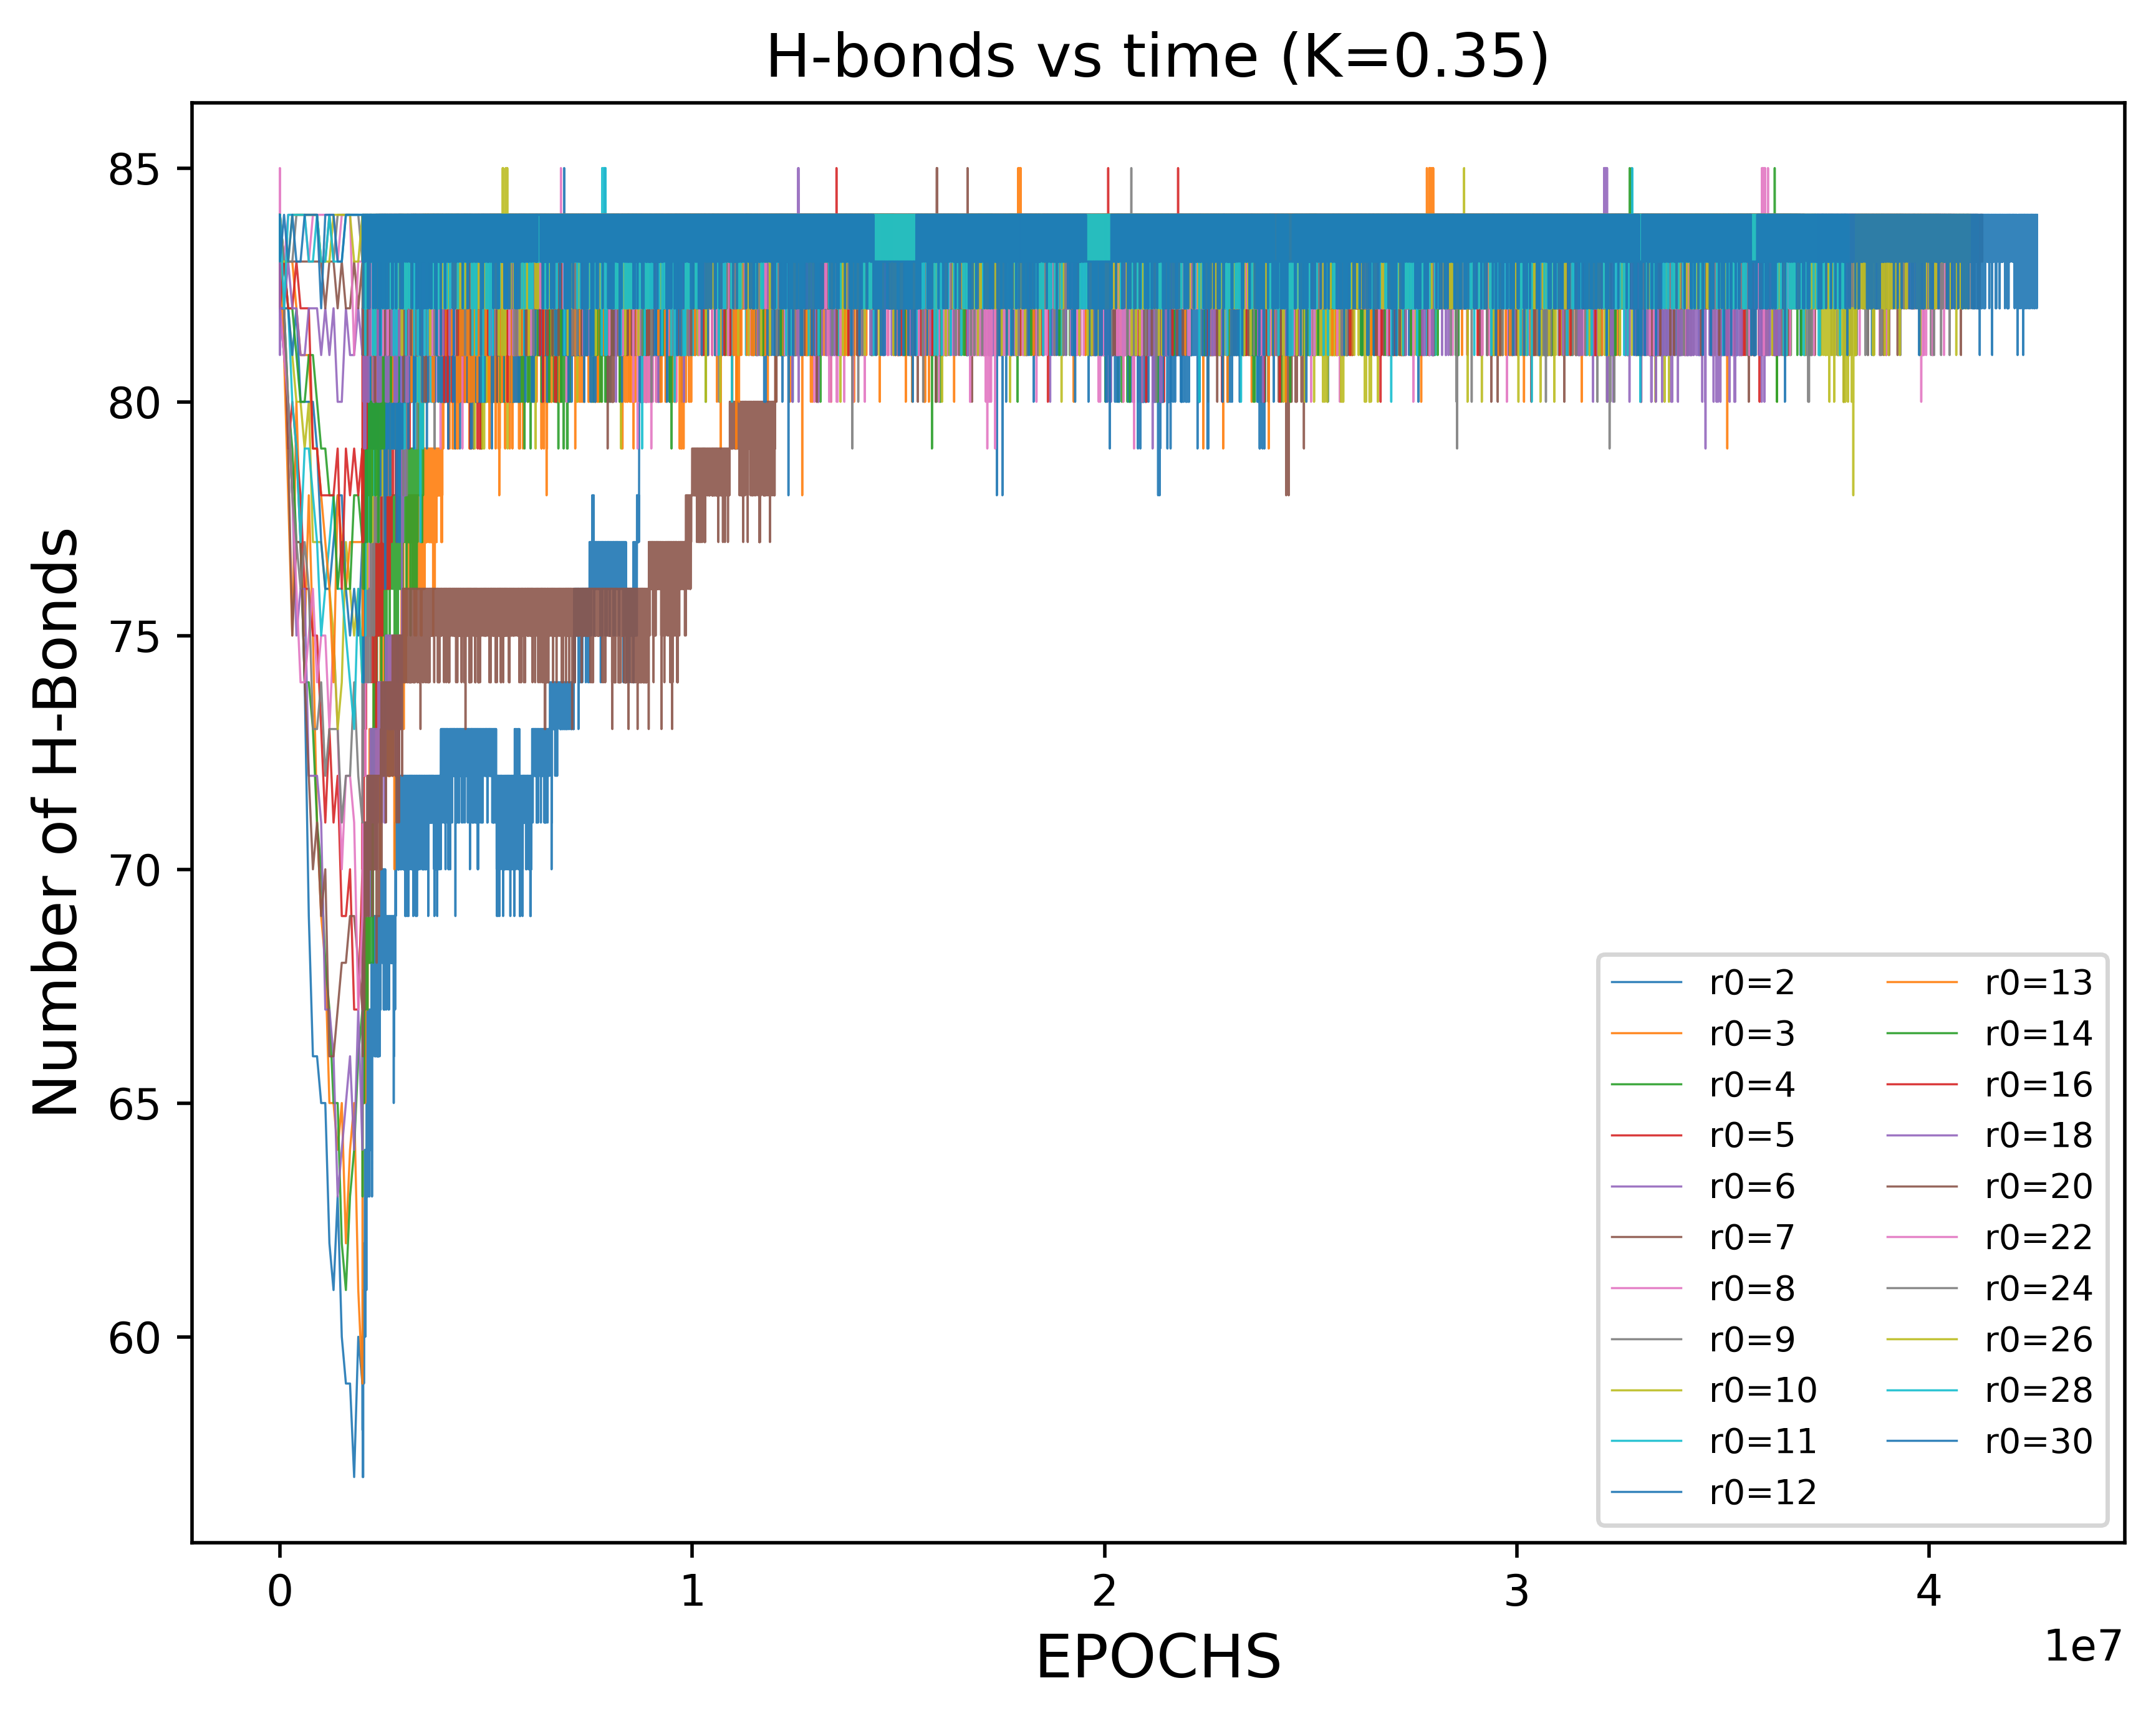

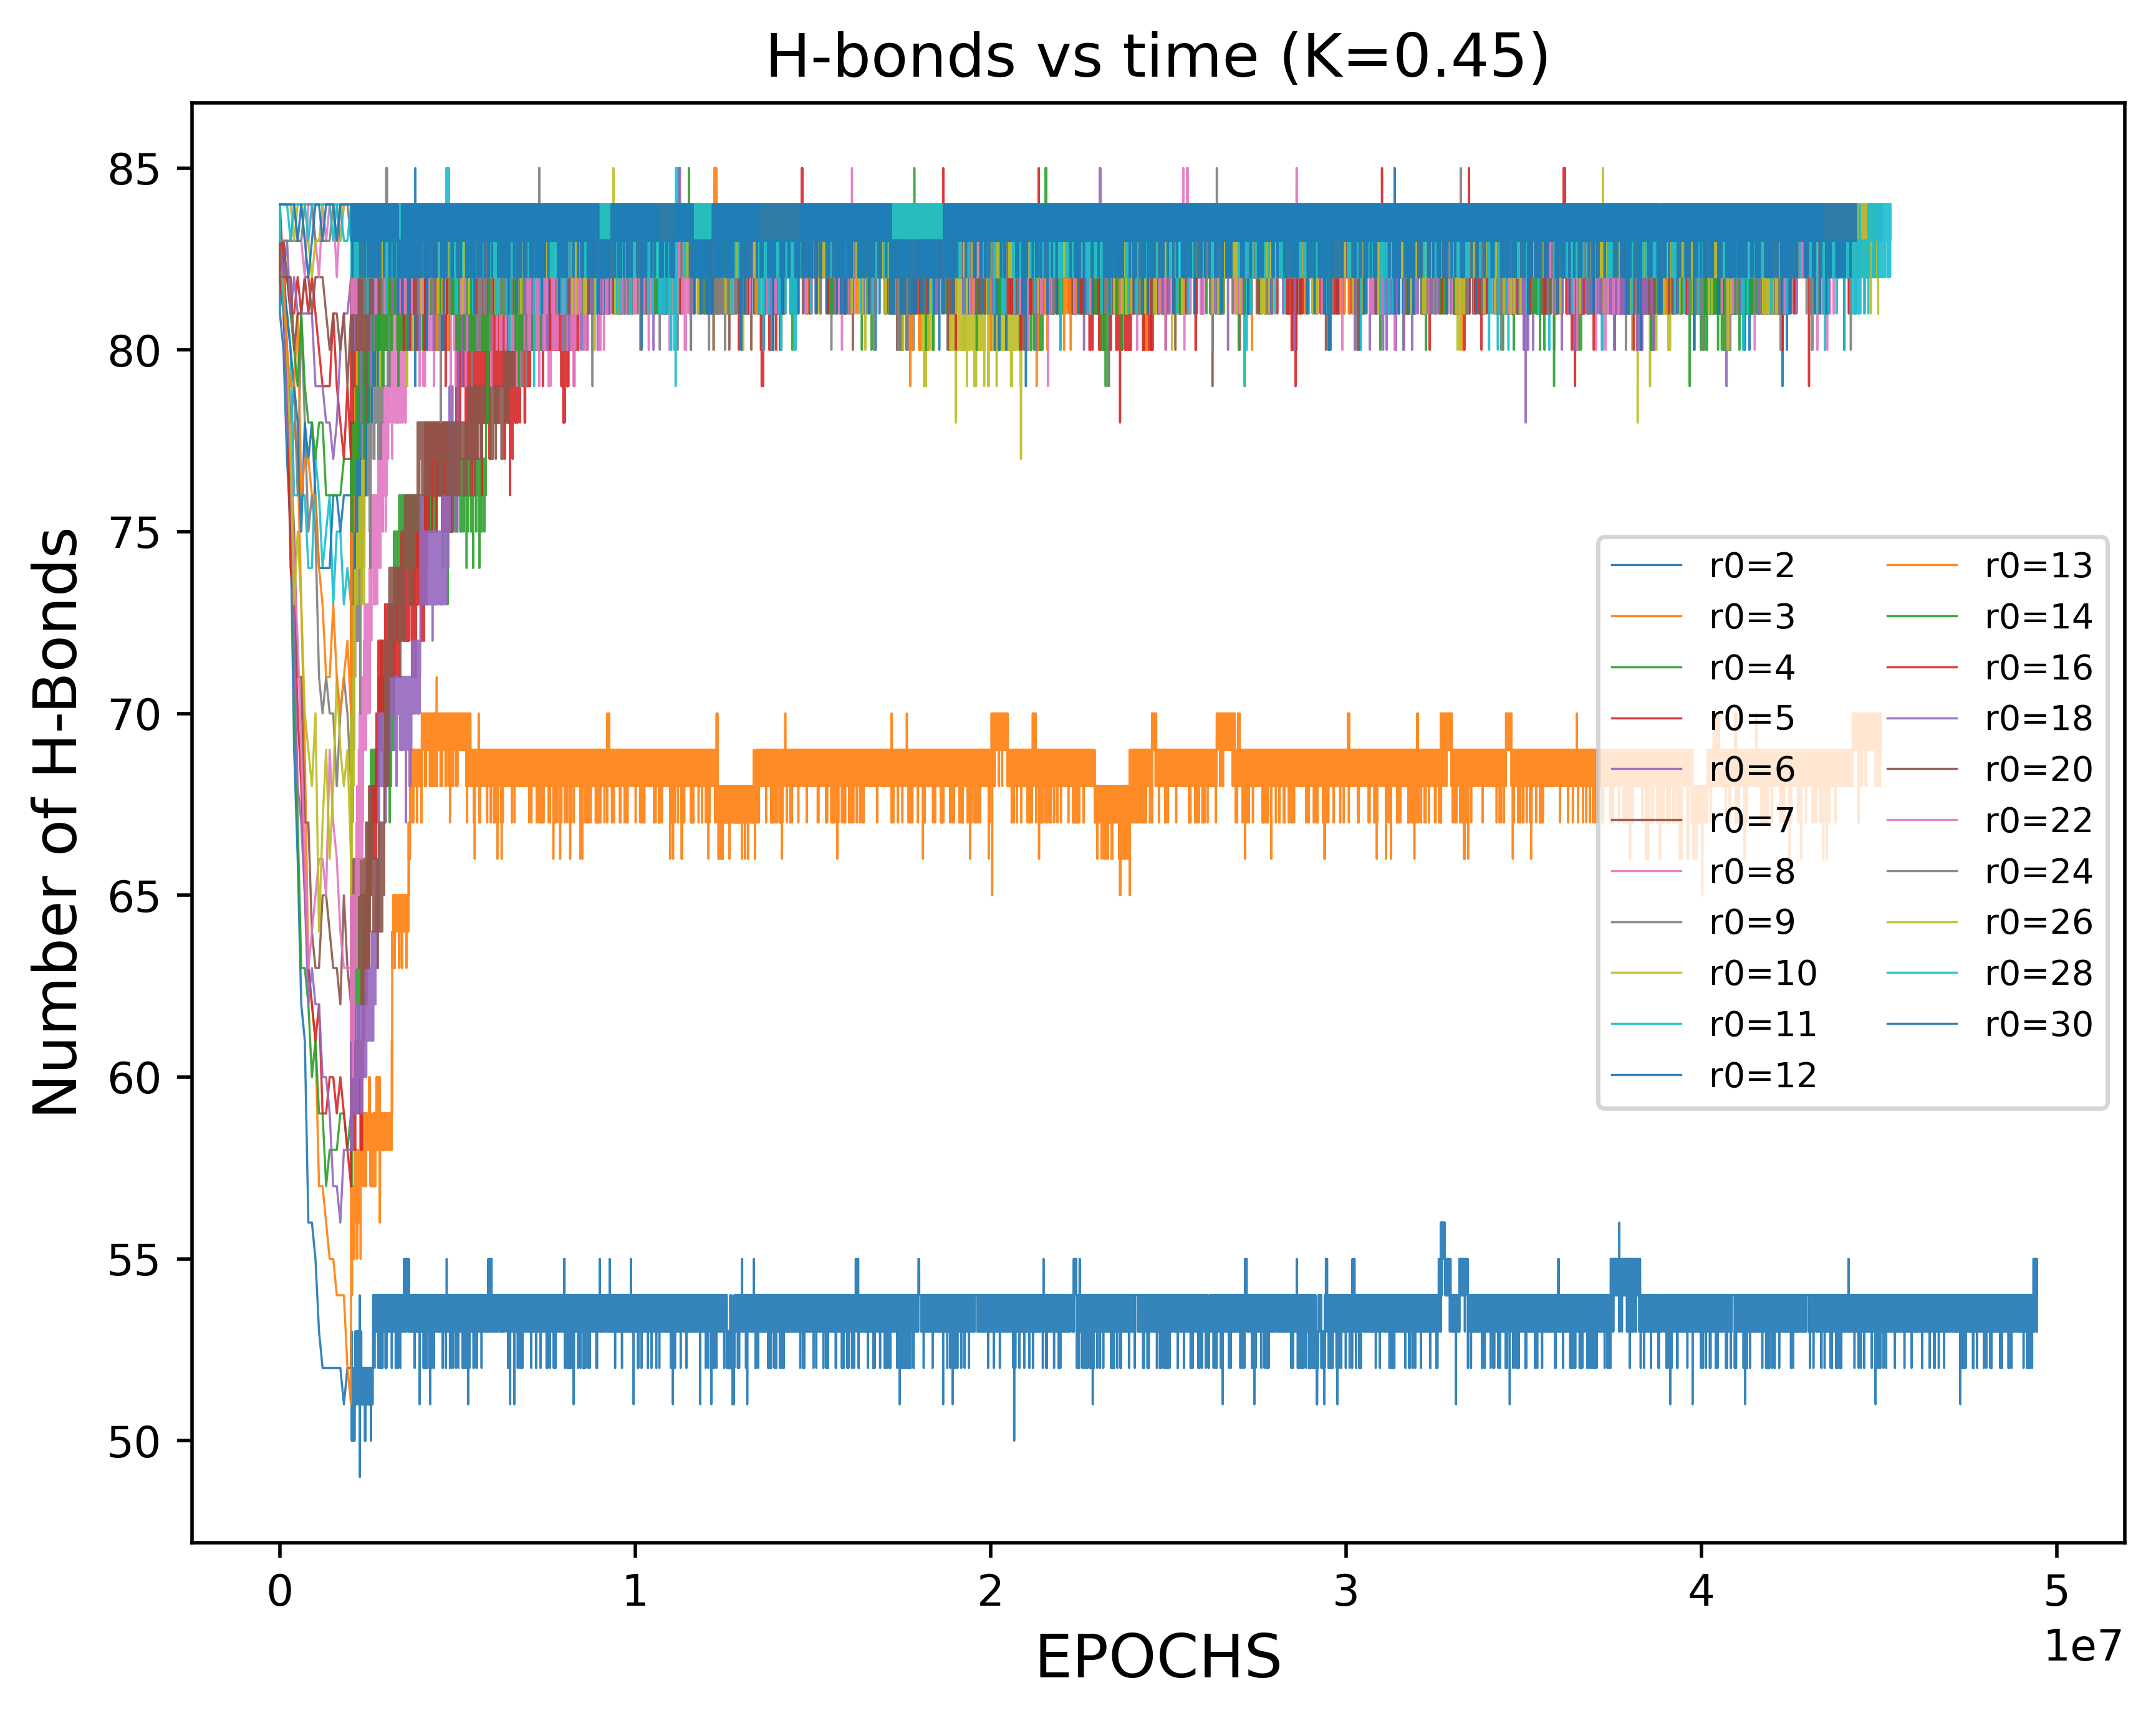

In [4]:
import matplotlib.pyplot as plt

r0_values = [2,3,4,5,6,7,8,9,10,11,12,13,14,16,18,20,22,24,26,28,30]
k_values = [0.35, 0.45]

for k in k_values:
    fig, ax = plt.subplots(figsize=(8,6), dpi=500)

    if k not in dfs:
        continue

    for r0 in r0_values:
        if r0 not in dfs[k]:
            continue
        df = dfs[k][r0]
        ax.plot(df["step"], df["hbond"],
                alpha=0.9, linewidth=0.5,
                label=f"r0={r0}")

    ax.set_title(f"H-bonds vs time (K={k})", fontsize=14)
    ax.set_xlabel("EPOCHS", fontsize=14)
    ax.set_ylabel("Number of H-Bonds", fontsize=14)

    # With many curves, legend can get huge; you can comment it out or shrink it:
    ax.legend(fontsize=8, ncol=2, frameon=True)

    plt.show()

In [ ]:
def steady_cutoff_by_hbonds(df,
                            tail_frac=0.10,
                            band=3.0,
                            min_stay=100000,
                            ):
    """
    Returns cutoff step where steady state begins, based on hbond convergence.
    df must have columns: 'step', 'hbond' (sorted by step).
    """
    d = df[["step", "hbond"]].dropna().sort_values("step").reset_index(drop=True)
    n = len(d)
    if n == 0:
        return None

    tail_n = int(n * tail_frac)
    plateau = d["hbond"].iloc[-tail_n:].median()  # robust plateau estimate

    in_band = (d["hbond"] >= plateau - band) & (d["hbond"] <= plateau + band)

    # Find earliest index i such that stable is True for the next min_stay points
    stable_run = in_band.rolling(min_stay, min_periods=min_stay).sum() >= min_stay
    idx = stable_run.idxmax() if stable_run.any() else None

    if idx is None:
        # fallback: if never "stays", cut at start of tail window
        return int(d["step"].iloc[-tail_n])

    # rolling window marks the END of the first full stable block; shift back
    start_idx = max(0, idx - (min_stay - 1))
    return int(d["step"].iloc[start_idx])

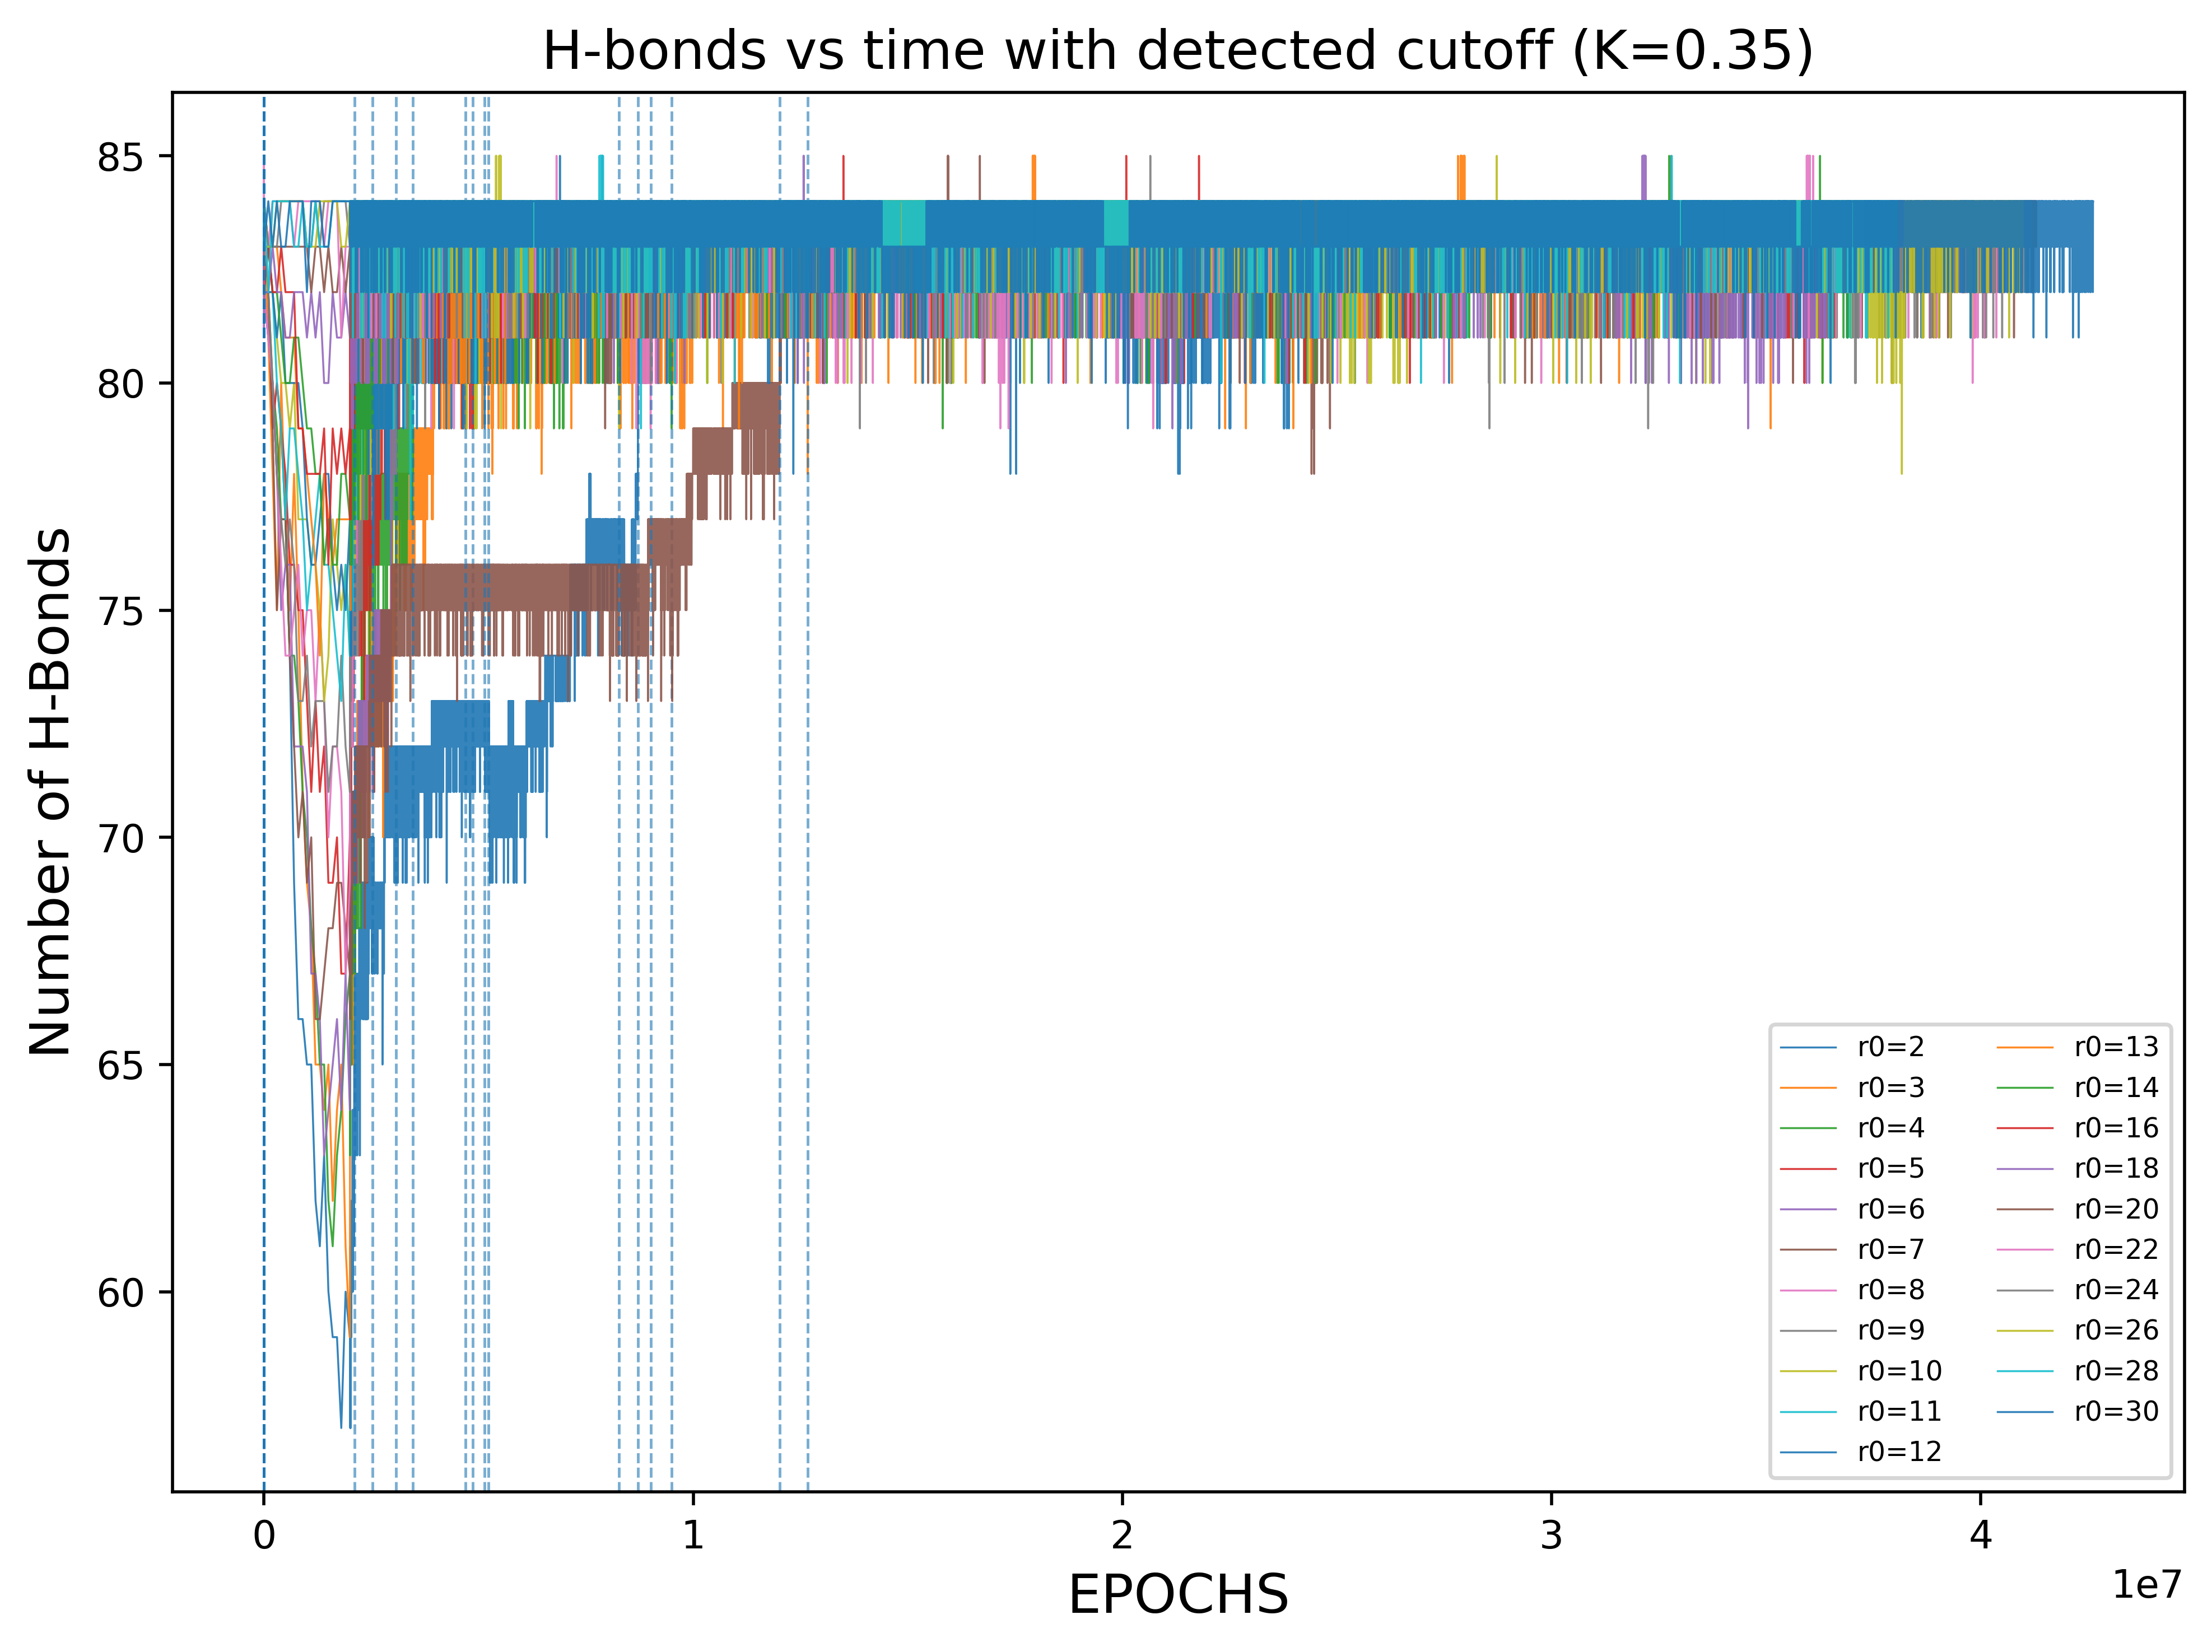

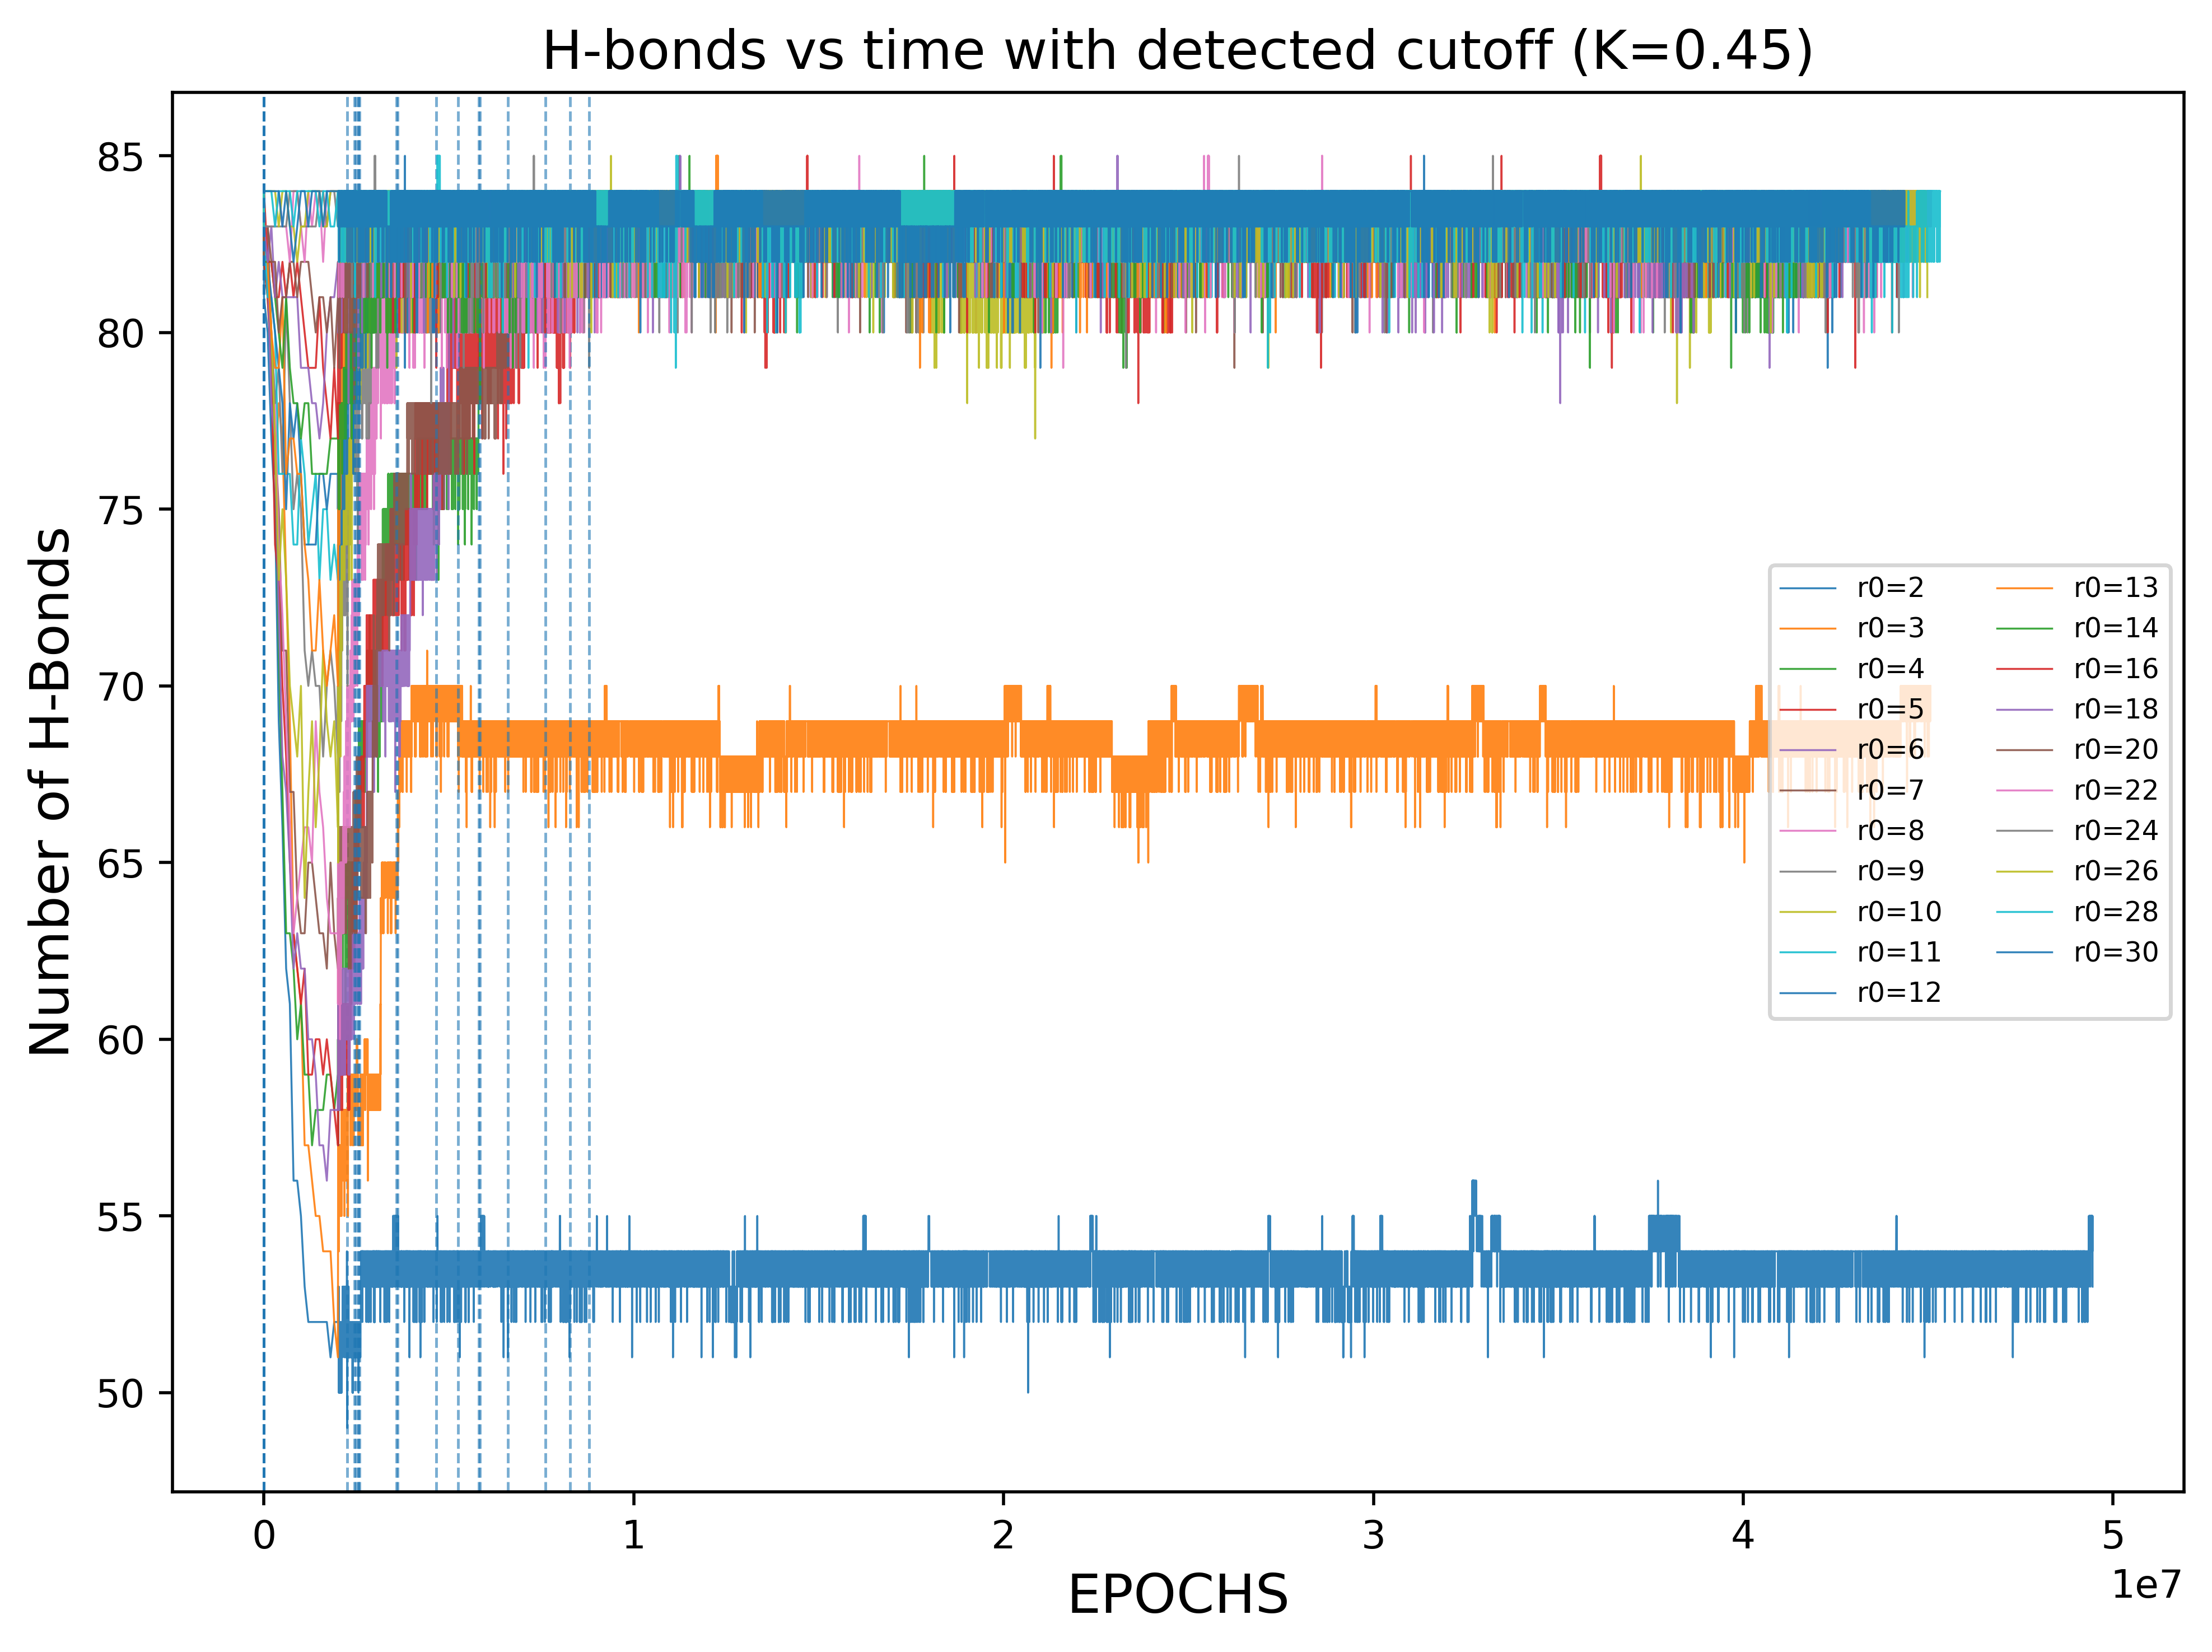

In [30]:
import matplotlib.pyplot as plt

source = dfs

# Parameters for cutoff detection
TAIL_FRAC = 0.10
BAND = 4.0
MIN_STAY_STEPS = 5000  # adjust (e.g. 1e6 or 2e6)

cutoffs = {}      # cutoffs[k][r0] = cutoff_step
dfs_ss = {}       # steady-state cropped dfs: dfs_ss[k][r0]

for k, by_r0 in source.items():
    cutoffs[k] = {}
    dfs_ss[k] = {}
    for r0, df in by_r0.items():
        c = steady_cutoff_by_hbonds(
            df,
            tail_frac=TAIL_FRAC,
            band=BAND,
            min_stay=MIN_STAY_STEPS,
        )
        cutoffs[k][r0] = c
        dfs_ss[k][r0] = df[df["step"] >= c].reset_index(drop=True)

# ---- Plot hbonds time series with vertical cutoff lines (one figure per k) ----
for k, by_r0 in source.items():
    fig, ax = plt.subplots(figsize=(8, 6), dpi=500)

    for r0, df in by_r0.items():
        ax.plot(df["step"], df["hbond"], linewidth=0.5, alpha=0.9, label=f"r0={r0}")

        c = cutoffs[k][r0]
        ax.axvline(c, linestyle="--", linewidth=0.7, alpha=0.6)

    ax.set_title(f"H-bonds vs time with detected cutoff (K={k})", fontsize=14)
    ax.set_xlabel("EPOCHS", fontsize=14)
    ax.set_ylabel("Number of H-Bonds", fontsize=14)

    
    ax.legend(fontsize=7, ncol=2, frameon=True)

    plt.tight_layout()
    plt.show()

In [37]:
#### BASIC STATISTICS OF STEADY STATE REGION
import numpy as np
import pandas as pd

r0_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 18, 20, 22, 24, 26, 28, 30]

stats_data = []
for k, by_r0 in dfs_ss.items():
    for r0 in r0_values:
        if r0 not in by_r0:
            continue

        df = by_r0[r0]

        # signed force: +|F| if dist > r0, -|F| if dist < r0
        # np.sign gives -1, 0, +1; equality -> 0 (force becomes 0 at exact r0)
        signed_force = np.sign(df["dist"].to_numpy() - r0) * df["force_mag"].to_numpy()

        stats_data.append({
            "k": k,
            "r_0": float(r0),

            "F mean": signed_force.mean(),
            "F std": signed_force.std(ddof=0),

            "|F| mean": df["force_mag"].mean(),
            "|F| std": df["force_mag"].std(ddof=0),

            "dist mean": df["dist"].mean(),
            "dist std": df["dist"].std(ddof=0),
            "hbonds mean": df["hbond"].mean(),
        })

stats_df = pd.DataFrame(stats_data).sort_values(["k", "r_0"])
print(stats_df)

       k   r_0    F mean     F std  |F| mean   |F| std  dist mean  dist std  \
0   0.35   2.0  0.157563  0.170087  0.189197  0.134014   2.450179  0.485963   
1   0.35   3.0  0.119584  0.177795  0.173536  0.125684   3.341669  0.507984   
2   0.35   4.0  0.099229  0.181560  0.165959  0.123564   4.283513  0.518744   
3   0.35   5.0  0.094806  0.182897  0.165500  0.122676   5.270874  0.522563   
4   0.35   6.0  0.089028  0.186268  0.165659  0.123202   6.254364  0.532196   
5   0.35   7.0  0.083138  0.181121  0.159437  0.119568   7.237538  0.517488   
6   0.35   8.0  0.079455  0.186552  0.162393  0.121421   8.227015  0.533005   
7   0.35   9.0  0.076358  0.187401  0.161055  0.122519   9.218165  0.535432   
8   0.35  10.0  0.074110  0.185107  0.158884  0.120469  10.211743  0.528876   
9   0.35  11.0  0.074347  0.181371  0.156941  0.117441  11.212419  0.518202   
10  0.35  12.0  0.065313  0.187528  0.157985  0.120305  12.186607  0.535795   
11  0.35  13.0  0.063655  0.189074  0.158963  0.1205

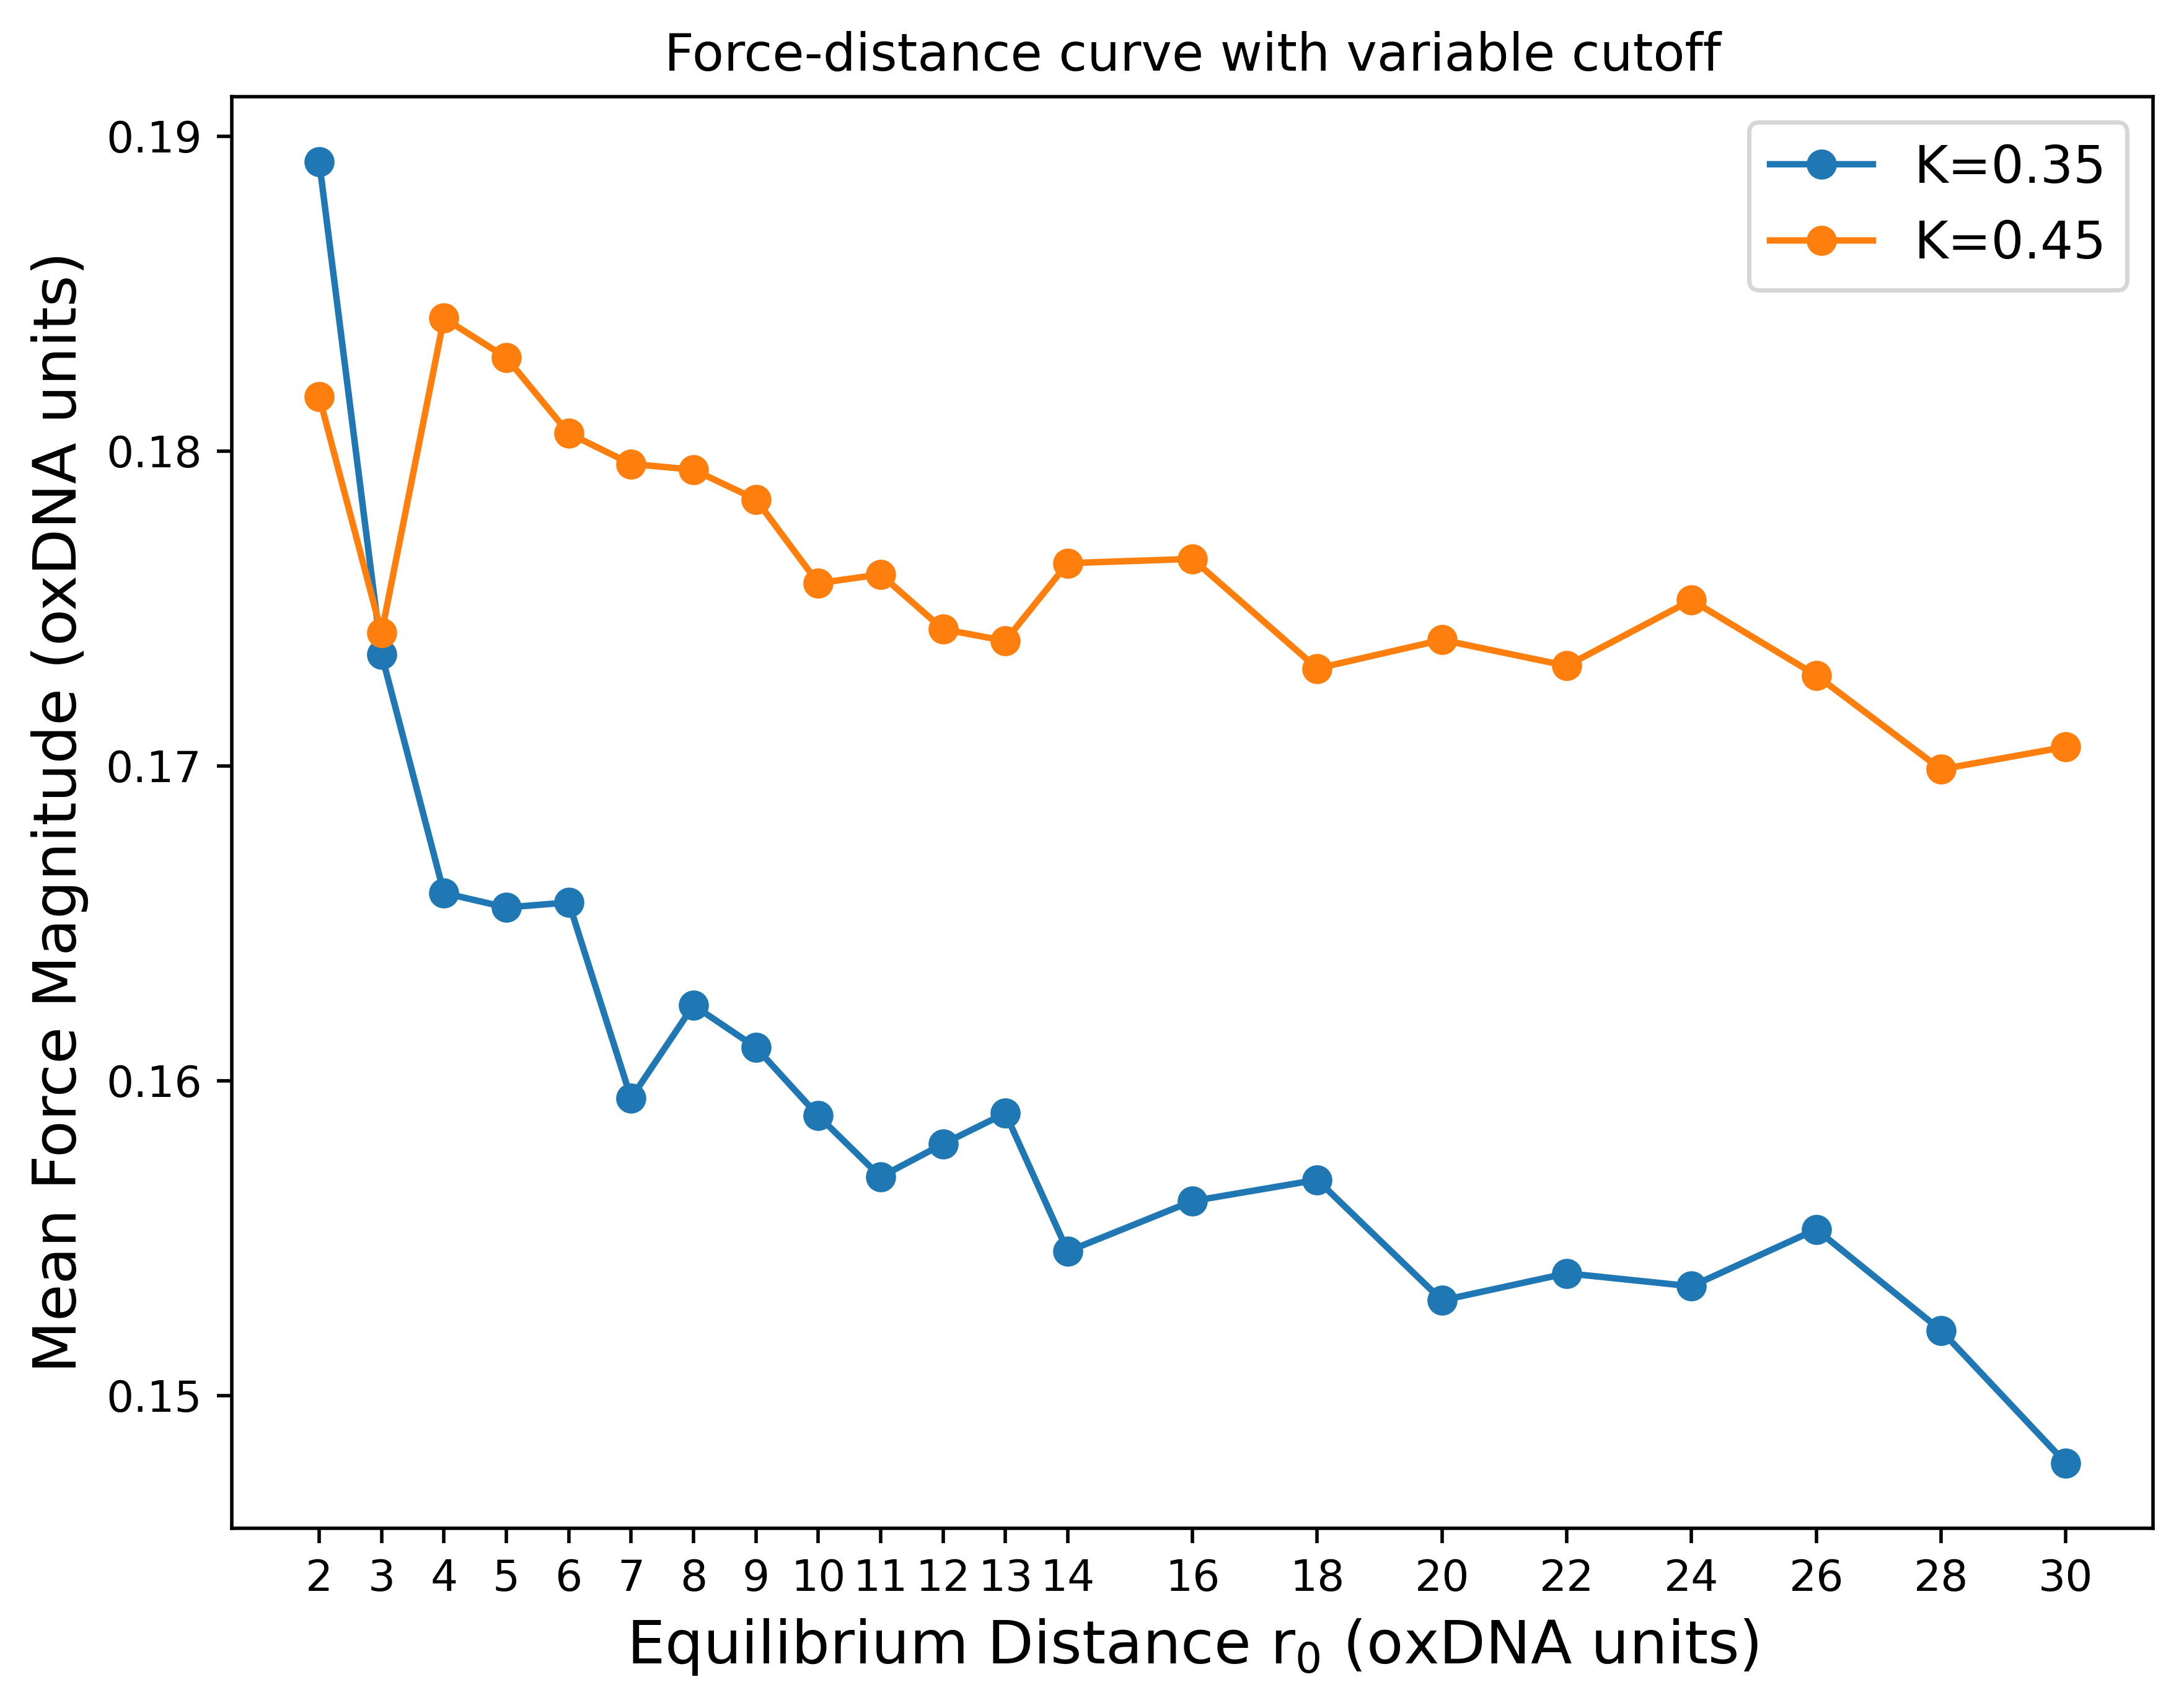

In [38]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.35, "K=0.35"), (0.45, "K=0.45")]:
    sub = stats_df[stats_df["k"] == k].sort_values("r_0")
    ax.plot(sub["r_0"], sub["|F| mean"], marker="o", label=label)
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("Mean Force Magnitude (oxDNA units)", fontsize=14)
ax.set_title("Force-distance curve with variable cutoff")
ax.legend(fontsize=12)

plt.show()

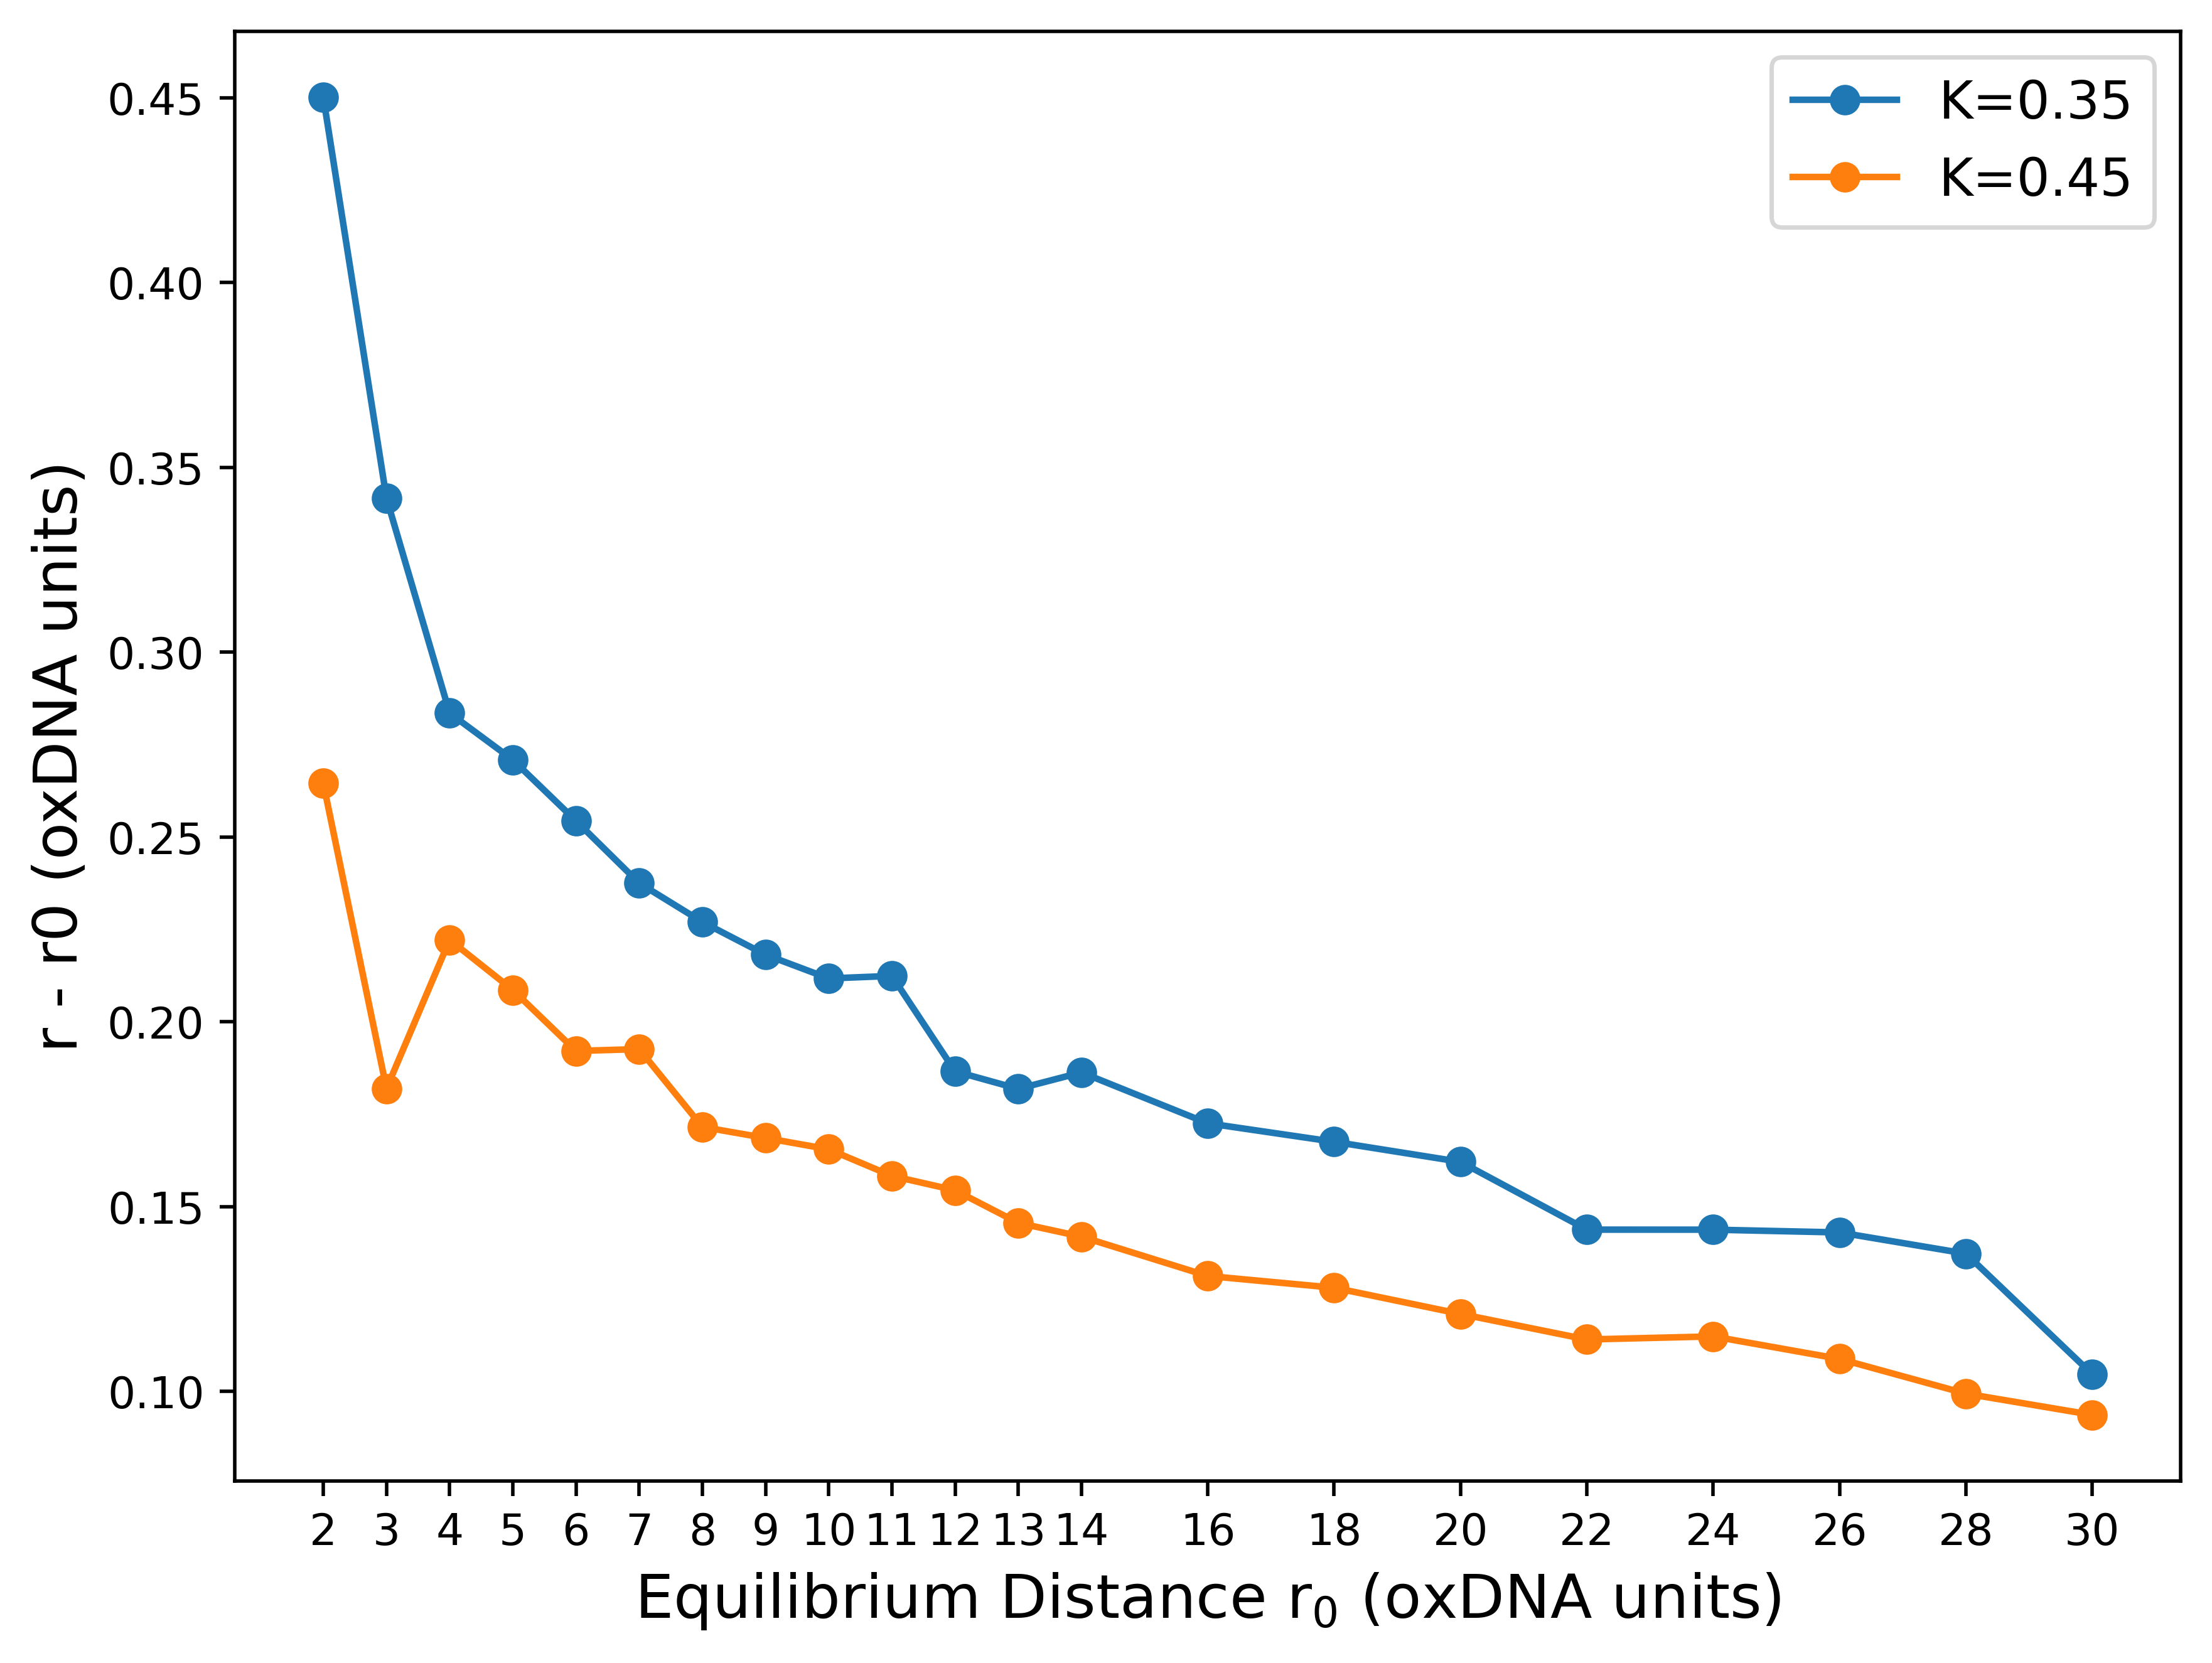

In [36]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.35, "K=0.35"), (0.45, "K=0.45")]:
    sub = stats_df[stats_df["k"] == k].sort_values("r_0")
    y = sub["dist mean"] - sub["r_0"]
    ax.plot(sub["r_0"], y, marker="o", label=label)
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("r - r0 (oxDNA units)", fontsize=14)
ax.legend(fontsize=12)

plt.show()

In [26]:
CUTOFF = 1.5e7  # 2,500,000

dfs_cfiltered = {}  # dfs_cfiltered[k][r0] = cutoff-filtered df

for k, by_r0 in dfs.items():
    dfs_cfiltered[k] = {}
    for r0, df in by_r0.items():
        dfs_cfiltered[k][r0] = df[df["step"] >= CUTOFF].reset_index(drop=True)

In [27]:
#### BASIC STATISTICS OF STEADY STATE REGION
import numpy as np
import pandas as pd

r0_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 18, 20, 22, 24, 26, 28, 30]

stats_data = []
for k, by_r0 in dfs_cfiltered.items():
    for r0 in r0_values:
        if r0 not in by_r0:
            continue

        df = by_r0[r0]

        # signed force: +|F| if dist > r0, -|F| if dist < r0
        # np.sign gives -1, 0, +1; equality -> 0 (force becomes 0 at exact r0)
        signed_force = np.sign(df["dist"].to_numpy() - r0) * df["force_mag"].to_numpy()

        stats_data.append({
            "k": k,
            "r_0": float(r0),

            "F mean": signed_force.mean(),
            "F std": signed_force.std(ddof=0),

            "|F| mean": df["force_mag"].mean(),
            "|F| std": df["force_mag"].std(ddof=0),

            "dist mean": df["dist"].mean(),
            "dist std": df["dist"].std(ddof=0),
            "hbonds mean": df["hbond"].mean(),
        })

stats_df = pd.DataFrame(stats_data).sort_values(["k", "r_0"])
print(stats_df)

       k   r_0    F mean     F std  |F| mean   |F| std  dist mean  dist std  \
0   0.35   2.0  0.157230  0.169189  0.188675  0.133221   2.449229  0.483396   
1   0.35   3.0  0.118510  0.177573  0.172824  0.125334   3.338601  0.507350   
2   0.35   4.0  0.099770  0.183089  0.167459  0.124230   4.285058  0.523110   
3   0.35   5.0  0.094665  0.181436  0.164262  0.122059   5.270470  0.518389   
4   0.35   6.0  0.086739  0.187672  0.165621  0.123749   6.247825  0.536204   
5   0.35   7.0  0.083335  0.180536  0.159169  0.119178   7.238101  0.515818   
6   0.35   8.0  0.078912  0.185210  0.161343  0.120409   8.225462  0.529171   
7   0.35   9.0  0.075722  0.188058  0.161039  0.123151   9.216348  0.537308   
8   0.35  10.0  0.073967  0.185223  0.159031  0.120366  10.211335  0.529209   
9   0.35  11.0  0.074462  0.182096  0.157077  0.118451  11.212749  0.520275   
10  0.35  12.0  0.064152  0.187402  0.157351  0.120315  12.183291  0.535435   
11  0.35  13.0  0.062986  0.187315  0.157400  0.1194

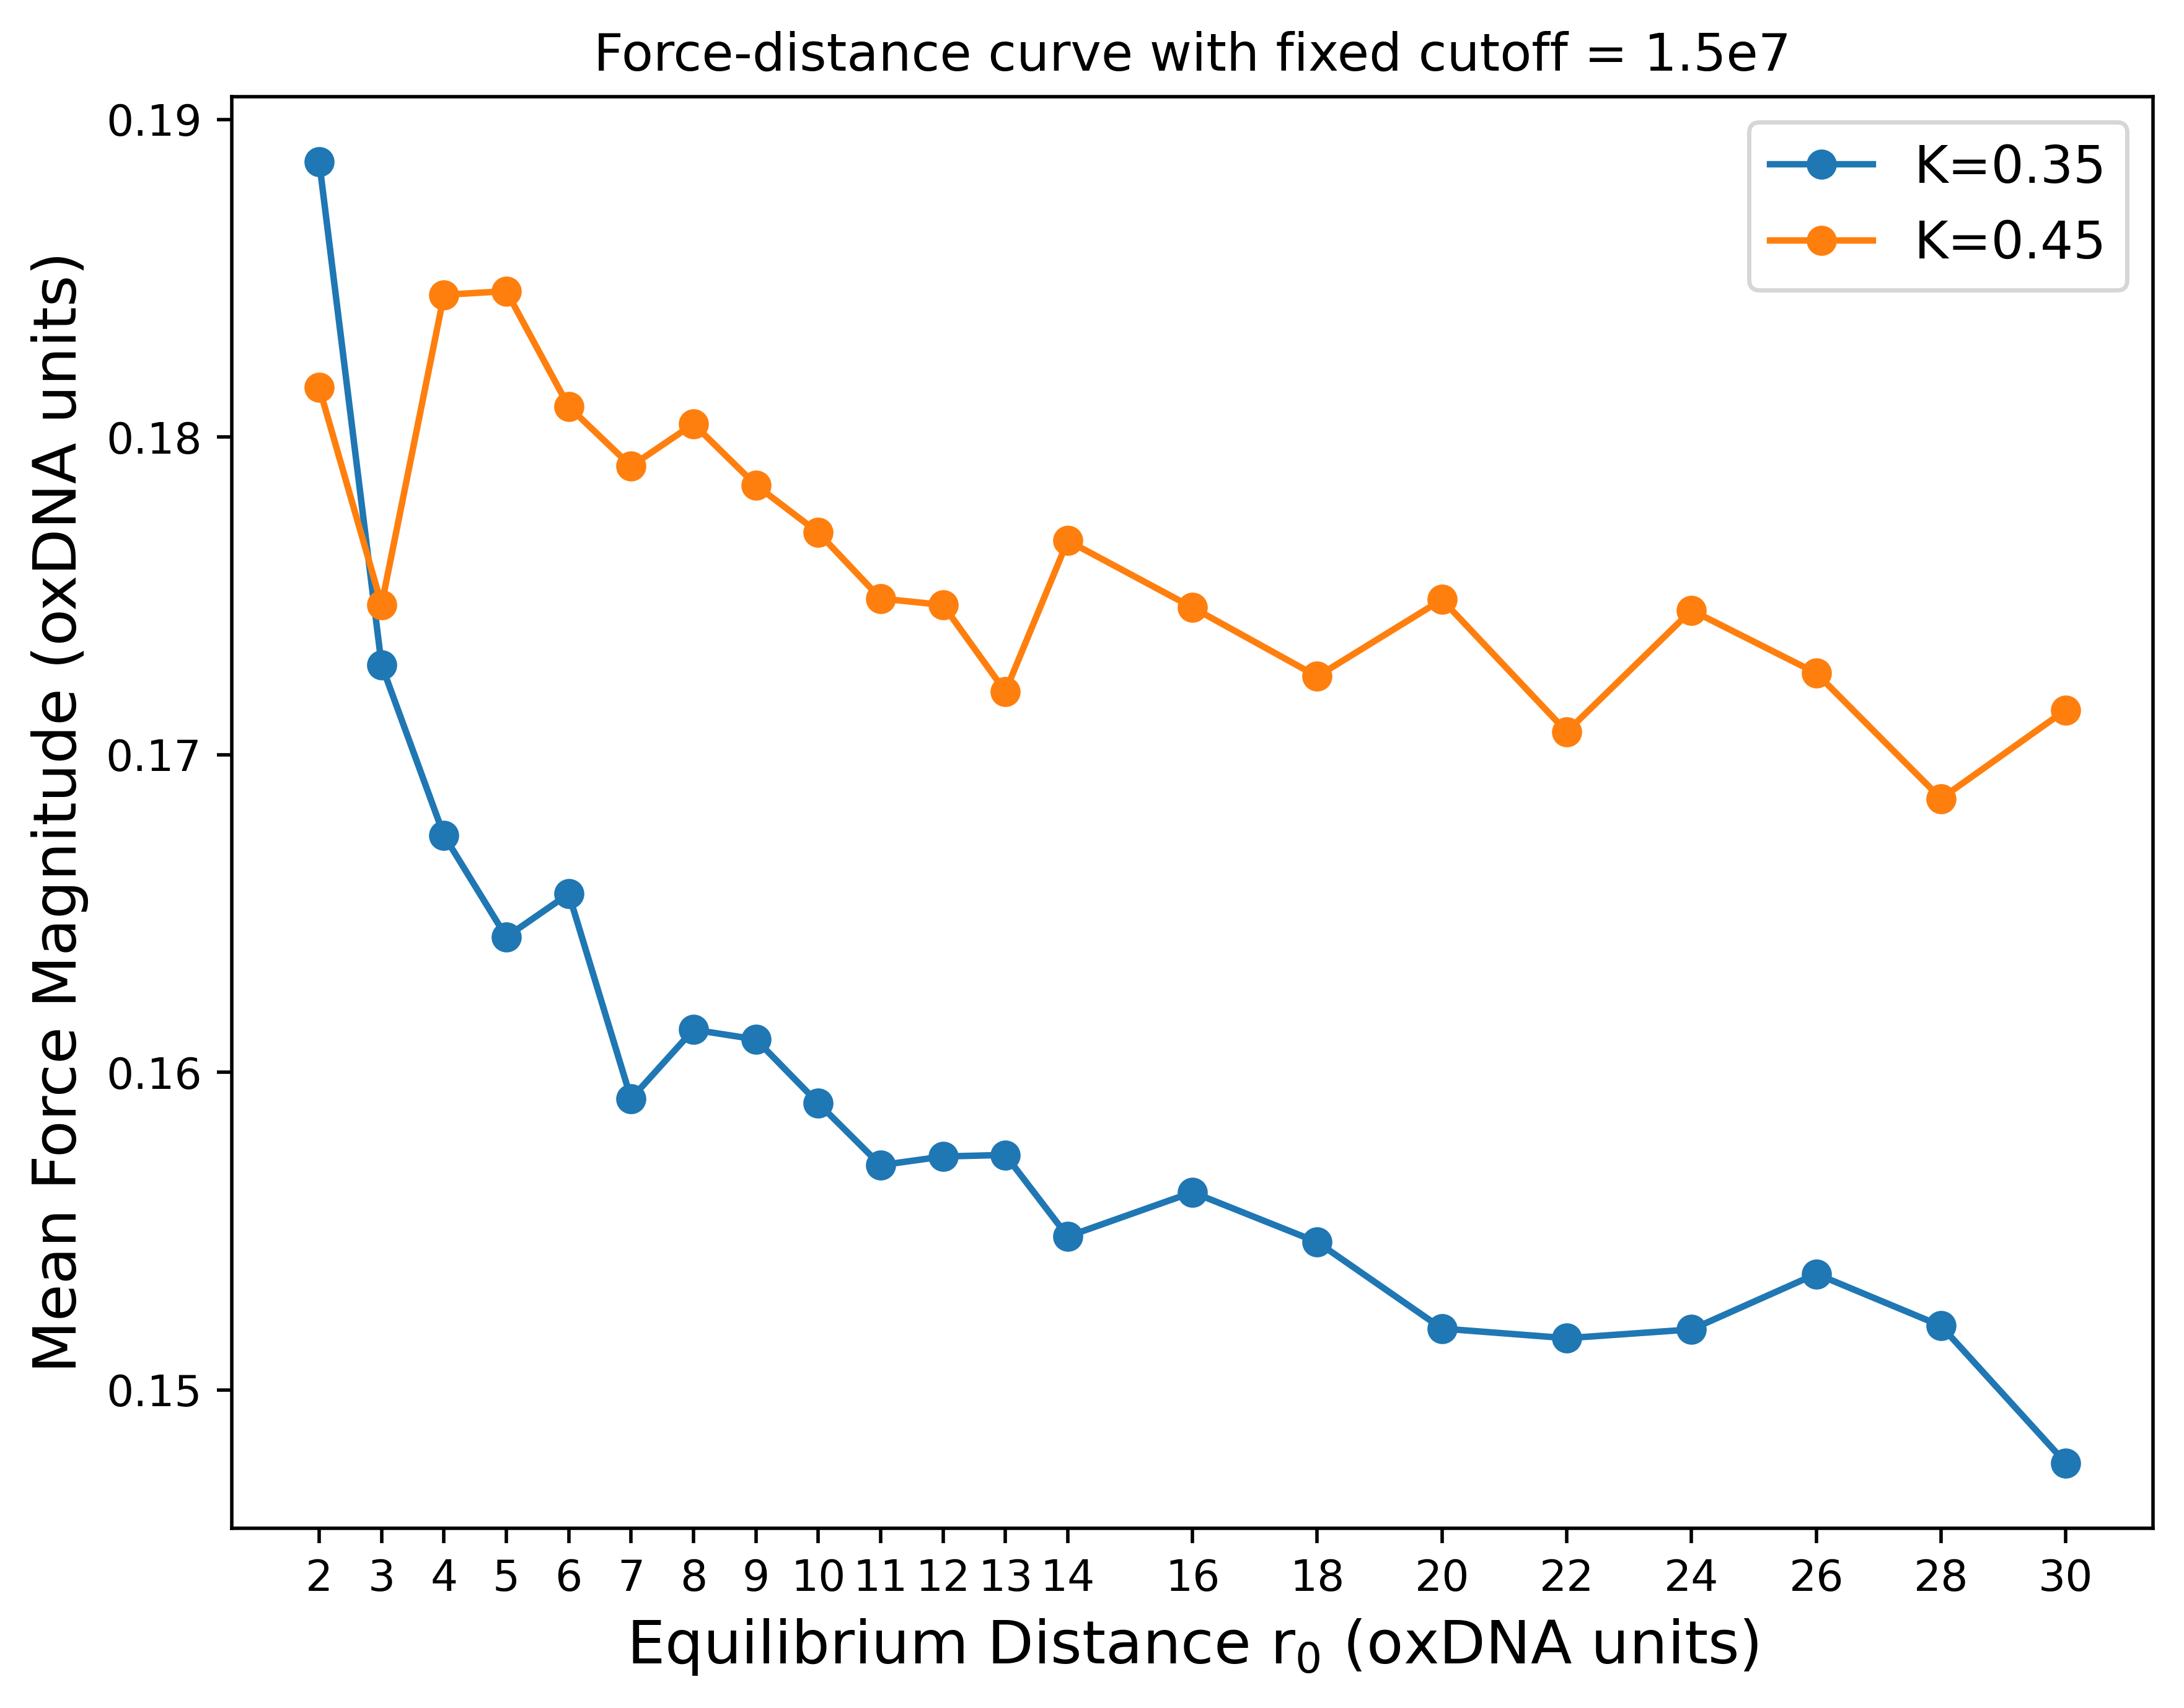

In [34]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.35, "K=0.35"), (0.45, "K=0.45")]:
    sub = stats_df[stats_df["k"] == k].sort_values("r_0")
    ax.plot(sub["r_0"], sub["|F| mean"], marker="o", label=label)
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("Mean Force Magnitude (oxDNA units)", fontsize=14)
ax.set_title("Force-distance curve with fixed cutoff = 1.5e7")
ax.legend(fontsize=12)

plt.show()

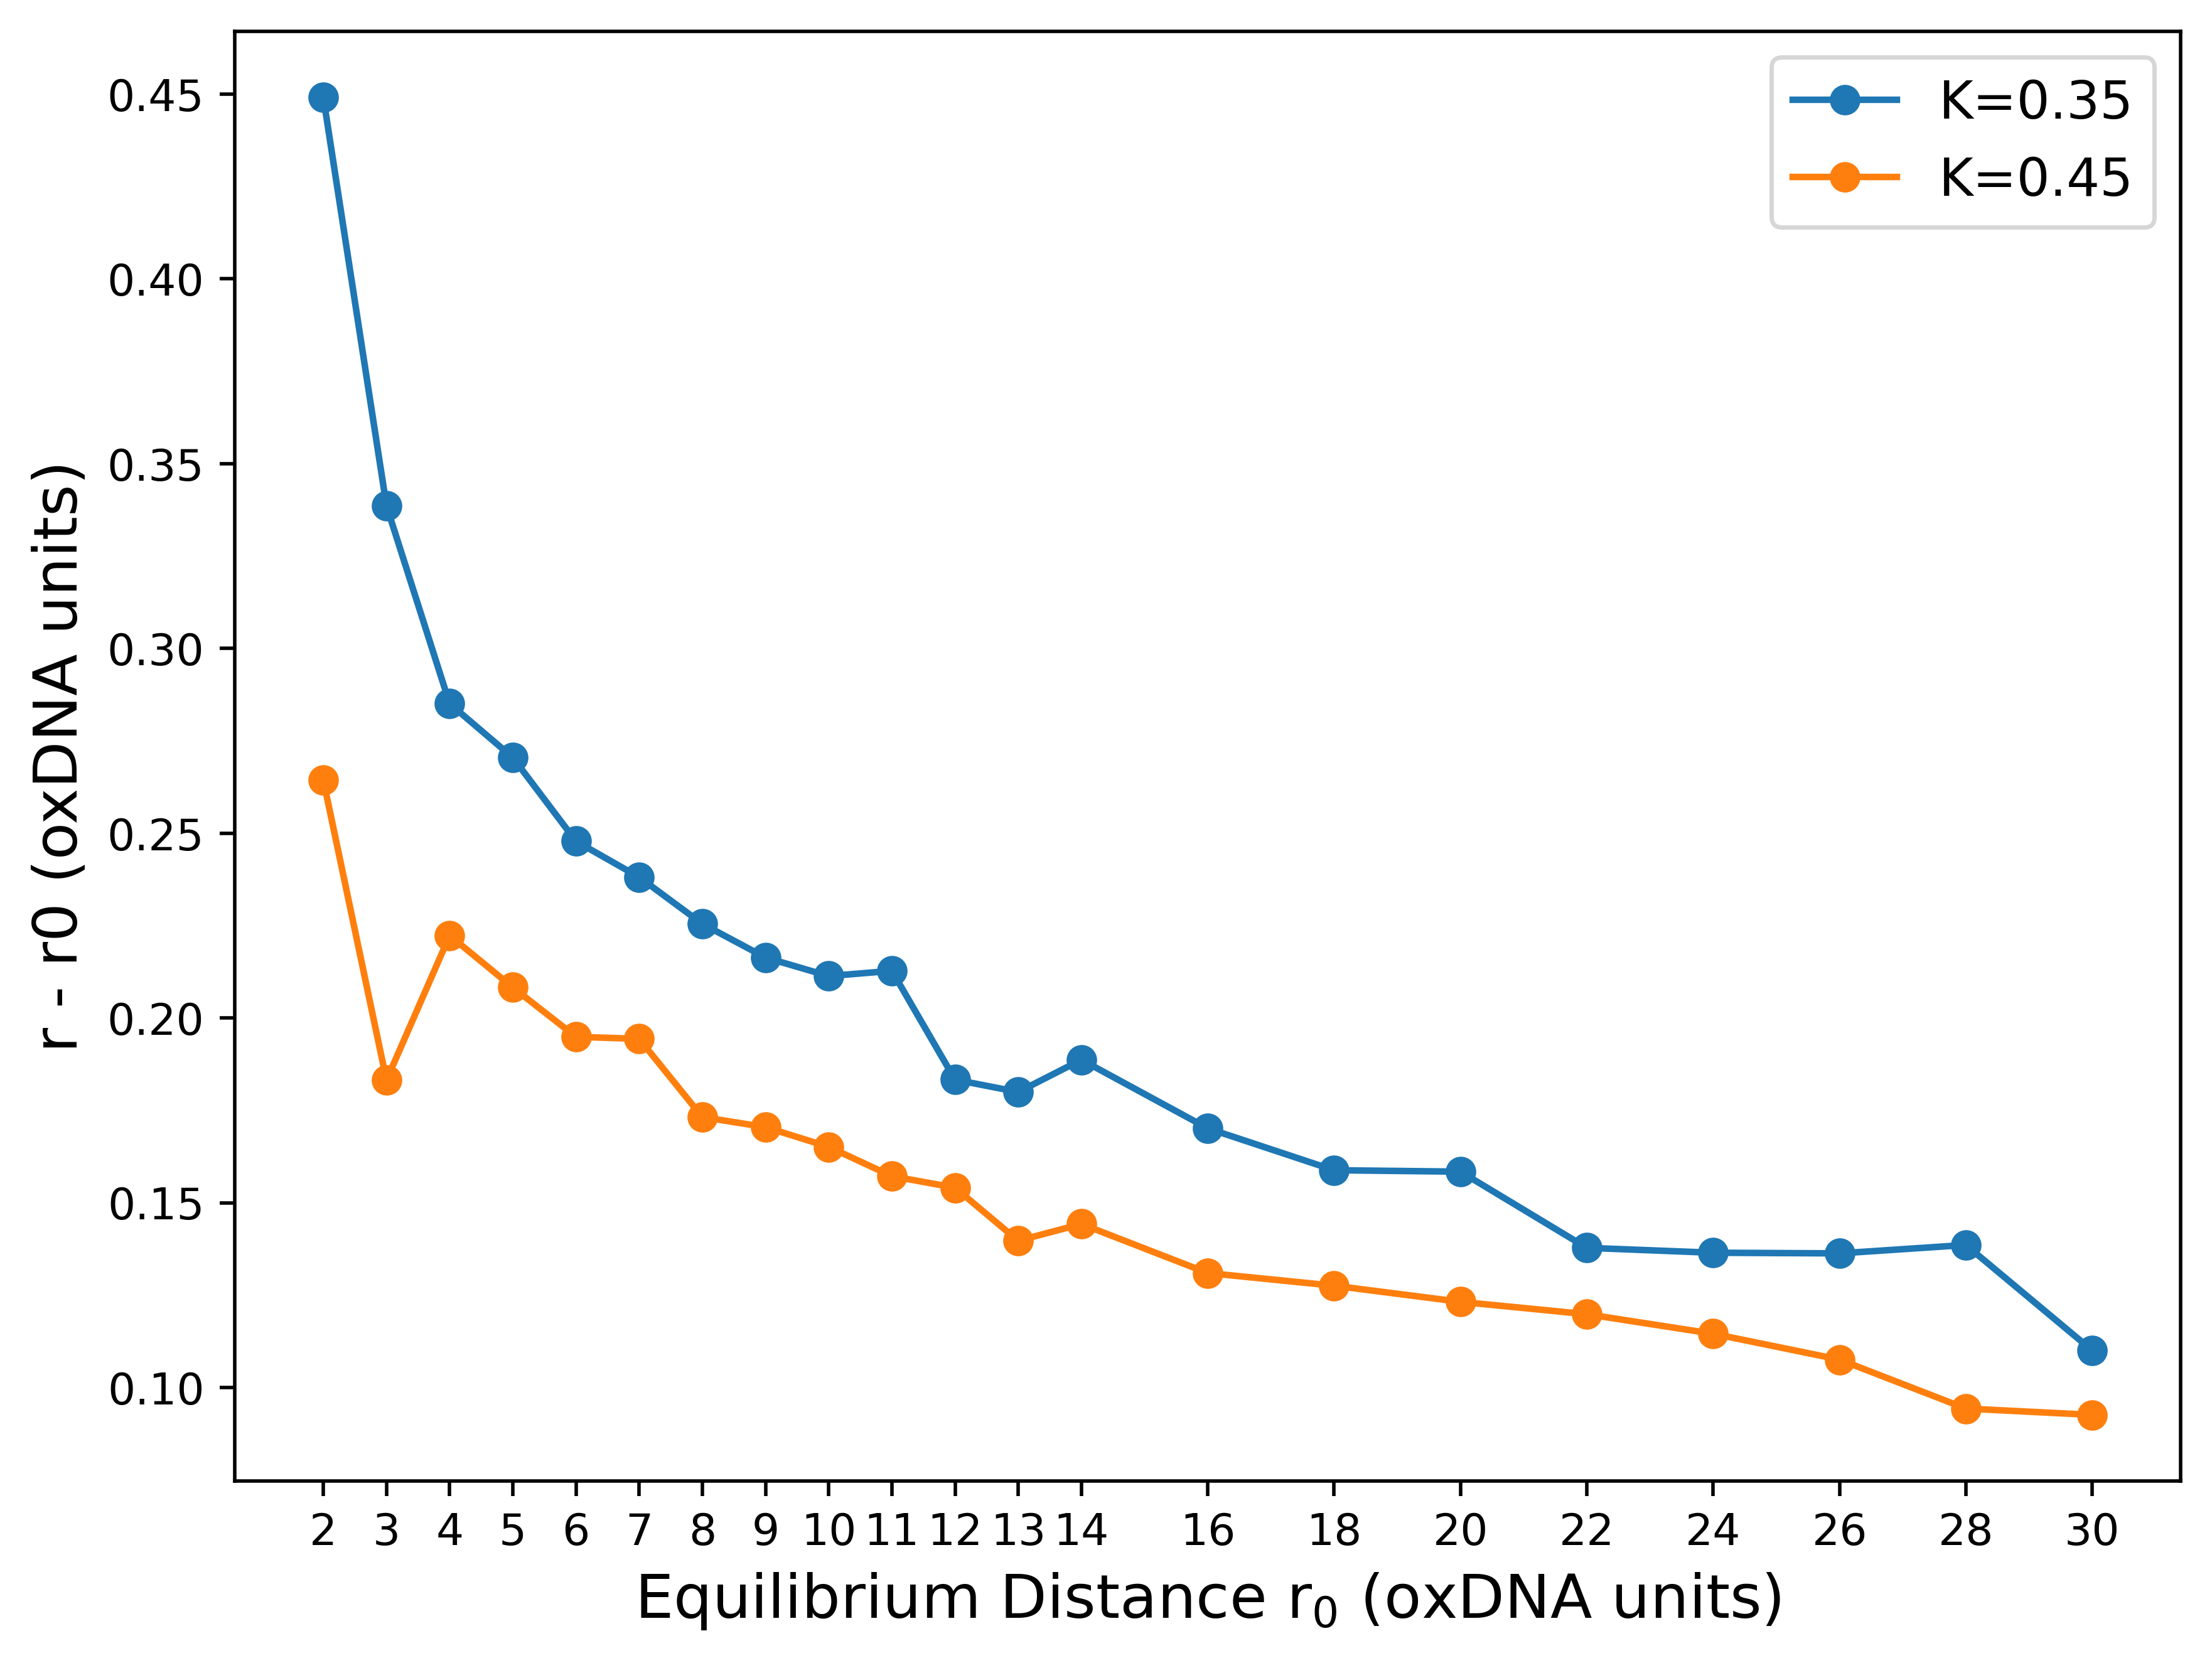

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.35, "K=0.35"), (0.45, "K=0.45")]:
    sub = stats_df[stats_df["k"] == k].sort_values("r_0")
    y = sub["dist mean"] - sub["r_0"]
    ax.plot(sub["r_0"], y, marker="o", label=label)
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("r - r0 (oxDNA units)", fontsize=14)
ax.legend(fontsize=12)

plt.show()

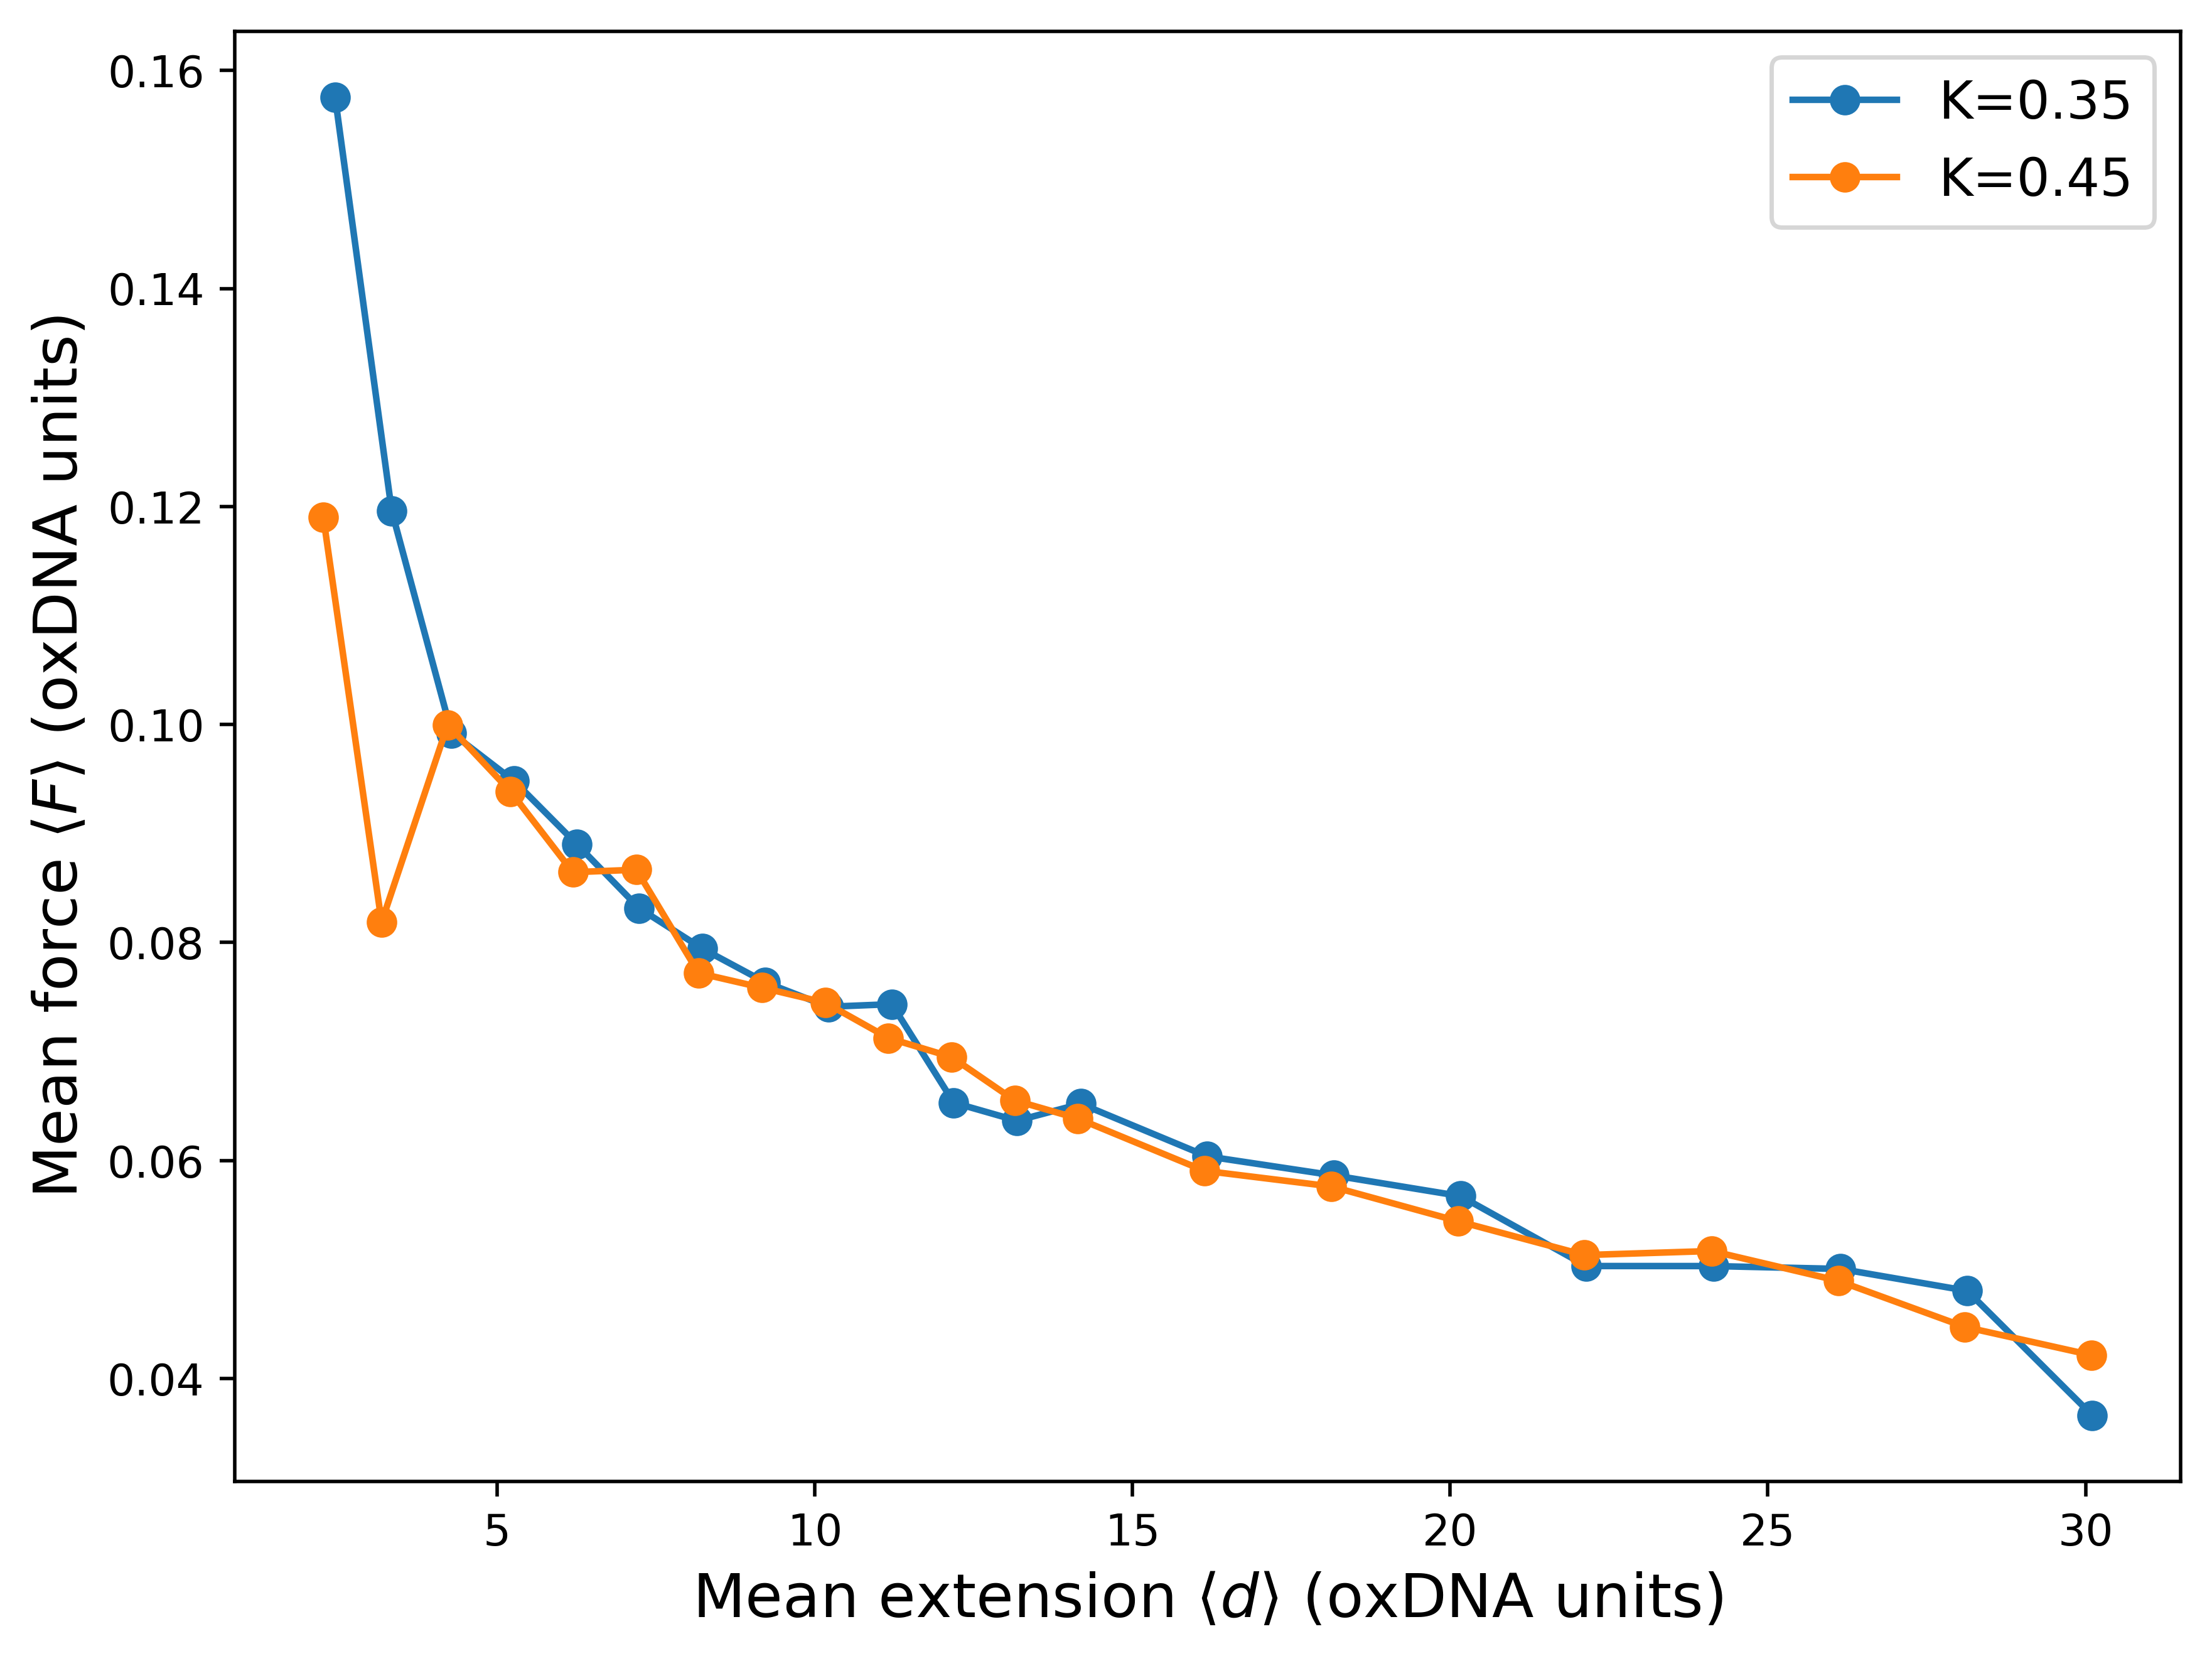

In [40]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6), dpi=500)

for k, label in [(0.35, "K=0.35"), (0.45, "K=0.45")]:
    sub = stats_df[stats_df["k"] == k].sort_values("dist mean")
    ax.plot(sub["dist mean"], sub["F mean"], marker="o", label=label)

ax.set_xlabel(r"Mean extension $\langle d \rangle$ (oxDNA units)", fontsize=14)
ax.set_ylabel(r"Mean force $\langle F \rangle$ (oxDNA units)", fontsize=14)
ax.legend(fontsize=12)

plt.show()